# Does New York build affordable housing on its most dangerous streets?

**Data Engineering and Visualization — Winter Semester 2026 — Project Milestone 1**
German International University, Faculty of Informatics and Computer Science

| | |
|---|---|
| **Housing & Development dataset** | [Affordable Housing Production by Building](https://data.cityofnewyork.us/Housing-Development/Affordable-Housing-Production-by-Building/hg8x-zxpr) (`hg8x-zxpr`) |
| **Transportation dataset** | [Motor Vehicle Collisions – Crashes](https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95) (`h9gi-nx95`) |
| **Integration key** | ZIP code × calendar year |
| **Analysis window** | 2018 – 2025 (eight complete calendar years) |
| **Interactive website** | see `app.py` and the deployment link in `README.md` |

---

## The question

New York City publishes, building by building, every affordable home it helps
finance. It also publishes, crash by crash, every collision its police respond
to. The two are never read together.

They should be. An affordable apartment is not only a rent number — it is a
front door that opens onto a particular street. A household that moves into a
subsidised unit does not get to choose the traffic outside it. If the city is
systematically placing its below-market housing on its most hostile streets,
then the people with the least housing choice are absorbing the most street
risk, and that is a distributional fact the city's own open data can speak to.

So: **when New York adds affordable units to a ZIP code, what kind of street
environment are those residents moving into?** We look in particular at
*vulnerable road users* — pedestrians and cyclists — because they are the
people a resident becomes the moment they step outside their building.

## What this notebook does

1. **Dataset overview** — what each dataset is, its size, shape, geography and
   time coverage, its known defects, and why this pair was chosen.
2. **Exploratory data analysis** — descriptive statistics and plots for each
   dataset separately.
3. **Pre-integration cleaning** — missing values, outliers, inconsistencies,
   format standardisation, duplicates. Every decision is justified in writing.
4. **Integration** — aggregation of both datasets to ZIP × year and the join.
5. **Post-integration cleaning** — join-induced nulls, redundant columns, dtypes.
6. **Validation** — plots that show the cleaning did what we claim.
7. **Ten research questions**, one chart each.
8. **Export** of the small processed tables the website reads.
9. **Limitations** — stated plainly, including why none of this is causal.
10. **Appendix** — dataset links and the full log of LLM prompts used.

---
# 0. Setup

In [1]:
import os
import re
import textwrap
import warnings

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["savefig.dpi"] = 110
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["figure.autolayout"] = True

# A single consistent palette so the notebook and the website look like one project.
HOUSING_COLOR = "#2a6f97"     # blue  -> housing & development
CRASH_COLOR = "#c1462e"       # red   -> transportation / crashes
NEUTRAL_COLOR = "#6b705c"
BOROUGH_COLORS = {
    "BRONX": "#8c5383",
    "BROOKLYN": "#2a6f97",
    "MANHATTAN": "#c1462e",
    "QUEENS": "#3f7d20",
    "STATEN ISLAND": "#d98e04",
}

RAW = os.path.join("data", "raw")
PROCESSED = os.path.join("data", "processed")
os.makedirs(PROCESSED, exist_ok=True)

# Analysis window. 2026 is deliberately excluded from both datasets: it is a
# partial year in each, and including it would invent a collapse in every
# time-series chart in this notebook.
YEAR_MIN, YEAR_MAX = 2018, 2025

print("pandas", pd.__version__, "| numpy", np.__version__)
print("analysis window:", YEAR_MIN, "-", YEAR_MAX)

pandas 3.0.3 | numpy 2.4.4
analysis window: 2018 - 2025


In [2]:
def show_missing(df, name, top=20):
    """Return a tidy missing-value table — used repeatedly, so it is a function."""
    miss = (
        df.isna().sum().to_frame("n_missing").assign(
            pct_missing=lambda t: 100 * t["n_missing"] / len(df)
        )
        .sort_values("n_missing", ascending=False)
    )
    miss = miss[miss["n_missing"] > 0].head(top)
    print(f"{name}: {len(df):,} rows x {df.shape[1]} columns | "
          f"{(df.isna().sum() > 0).sum()} columns contain missing values")
    return miss


def plot_missing(df, name, color, top=18):
    """Horizontal bar of the most-missing columns."""
    pct = (100 * df.isna().mean()).sort_values(ascending=False).head(top)
    pct = pct[pct > 0]
    if pct.empty:
        print(f"{name}: no missing values")
        return
    fig, ax = plt.subplots(figsize=(7, 0.32 * len(pct) + 1.2))
    ax.barh(pct.index[::-1], pct.to_numpy()[::-1], color=color)
    ax.set_xlabel("% of rows missing")
    ax.set_title(f"{name}: missing values by column")
    ax.xaxis.set_major_formatter(mticker.PercentFormatter())
    plt.show()


def iqr_bounds(series, k=1.5):
    """Classic Tukey fence. Returned rather than applied, so each use can decide."""
    q1, q3 = series.quantile(0.25), series.quantile(0.75)
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr


def thousands(ax, axis="y"):
    fmt = mticker.StrMethodFormatter("{x:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)

---
# 1. Dataset overview and why this pair

## 1.1 The housing dataset — `hg8x-zxpr`

**Affordable Housing Production by Building**, published by the NYC Department
of Housing Preservation and Development (HPD). One row per *building* in a
project that HPD financed since 2014. It carries 41 columns, of which the ones
that matter to us are:

* **Geography** — `borough`, `postcode`, `community_board`, `council_district`,
  `census_tract`, `neighborhood_tabulation_area`, `latitude`/`longitude`
* **Time** — `project_start_date`, `project_completion_date`,
  `building_completion_date`
* **Measures** — `total_units`, `all_counted_units`, and a full breakdown by
  affordability band (`extremely_low_income_units` through
  `middle_income_units`) and by bedroom count (`studio_units` … `_6_br_units`)

It is small — under 10,000 rows — which is exactly why it is useful: it is the
*signal* dataset, and every row is a deliberate public investment decision.

## 1.2 The transportation dataset — `h9gi-nx95`

**Motor Vehicle Collisions – Crashes**, published by NYPD. One row per police-
reported collision, 29 columns, roughly 2.2 million rows since 2012. Relevant
columns:

* **Geography** — `borough`, `zip_code`, `latitude`/`longitude`, plus street names
* **Time** — `crash_date`, `crash_time`
* **Measures** — persons injured/killed, split out for pedestrians, cyclists and
  motorists
* **Context** — `contributing_factor_vehicle_1` … `_5`, `vehicle_type_code1` … `_5`

## 1.3 Why a filtered slice, and which one

The full crash table would not survive a notebook, and the Socrata API caps a
single response at 1,000,000 rows. We therefore pull calendar years
**2018–2025** — 1,043,903 rows — paged in blocks of 250,000 with a stable
`$order=:id` so the paging cannot skip or duplicate records. See
`download_data.py`.

That window is not arbitrary:

* **It is complete at both ends.** 2026 is partial in both datasets (crash data
  ends 2026-11-03, housing completions end 2026-08-11). A partial final year
  would manufacture a downward trend in every line chart.
* **It matches the housing data's useful range.** HPD completions only become
  numerous from 2017 onward.
* **It contains the pandemic.** 2020–2021 is a natural experiment in traffic
  volume, and it would be a shame to cut it out.

## 1.4 Why these two can be integrated

Both datasets carry **ZIP code**, **borough** and **a date**. Neither has an
entity in common — a building is not a crash — so a row-level join would be
meaningless, and the project brief explicitly warns against joining merely
because a common attribute exists. Instead we aggregate **both sides to
ZIP × calendar year** and join on that. Section 4 justifies the choice of
granularity in detail.

In [3]:
HOUSING_RAW = os.path.join(RAW, "housing_raw.csv")
CRASH_RAW = os.path.join(RAW, "crashes_raw.csv")

for path in (HOUSING_RAW, CRASH_RAW):
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"{path} not found. Run `python download_data.py` first "
            "(it fetches both datasets from the NYC Open Data API)."
        )

housing_raw = pd.read_csv(HOUSING_RAW, low_memory=False)
crashes_raw = pd.read_csv(CRASH_RAW, low_memory=False)

print(f"housing : {housing_raw.shape[0]:>9,} rows x {housing_raw.shape[1]:>3} columns")
print(f"crashes : {crashes_raw.shape[0]:>9,} rows x {crashes_raw.shape[1]:>3} columns")

housing :     9,551 rows x  41 columns
crashes : 1,043,903 rows x  29 columns


In [4]:
# Column inventory for the housing dataset.
housing_raw.dtypes.to_frame("dtype").assign(
    n_unique=housing_raw.nunique(),
    pct_missing=(100 * housing_raw.isna().mean()).round(1),
    example=housing_raw.iloc[0],
)

,dtype,n_unique,pct_missing,example
project_id,int64,5928,0.000,68872
project_name,str,3979,0.000,177-06 WEXFORD TERRACE
project_start_date,str,2346,0.000,2026-06-30T00:00:00.000
project_completion_date,str,2066,19.000,NaN
building_id,float64,7478,20.400,"991,637.000"
house_number,str,3154,0.000,177-06
street_name,str,1567,0.000,WEXFORD TERRACE
borough,str,5,0.000,Queens
postcode,float64,158,20.500,"11,432.000"
bbl,float64,6423,21.200,"4,098,350,023.000"


In [5]:
# Column inventory for the crash dataset.
crashes_raw.dtypes.to_frame("dtype").assign(
    n_unique=crashes_raw.nunique(),
    pct_missing=(100 * crashes_raw.isna().mean()).round(1),
    example=crashes_raw.iloc[0],
)

,dtype,n_unique,pct_missing,example
crash_date,str,2922,0.000,2023-10-16T00:00:00.000
crash_time,str,1440,0.000,09:24
borough,str,5,31.900,BROOKLYN
zip_code,float64,230,32.900,"11,217.000"
latitude,float64,82543,7.100,40.678
longitude,float64,54731,7.100,-73.973
location,str,241522,7.100,"\n, \n(40.677715, -73.97326)"
on_street_name,str,13336,26.200,PARK PLACE
off_street_name,str,175143,73.900,NaN
cross_street_name,str,15271,50.500,7 AVENUE


In [6]:
housing_raw.head(3)

,project_id,project_name,project_start_date,project_completion_date,building_id,house_number,street_name,borough,postcode,bbl,bin,community_board,council_district,census_tract,neighborhood_tabulation_area,latitude,longitude,latitude_internal,longitude_internal,building_completion_date,reporting_construction_type,extended_affordability_status,prevailing_wage_status,extremely_low_income_units,very_low_income_units,low_income_units,moderate_income_units,middle_income_units,other_income_units,studio_units,_1_br_units,_2_br_units,_3_br_units,_4_br_units,_5_br_units,_6_br_units,unknown_br_units,counted_rental_units,counted_homeownership_units,all_counted_units,total_units
0,68872,177-06 WEXFORD TERRACE,2026-06-30T00:00:00.000,NaN,"991,637.000",177-06,WEXFORD TERRACE,Queens,"11,432.000","4,098,350,023.000","4,000,000.000",QN-08,24,466.000,QN06,40.713,-73.786,40.713,-73.787,NaN,New Construction,No,Non Prevailing Wage,NaN,NaN,9.000,NaN,NaN,NaN,NaN,9.000,NaN,NaN,NaN,NaN,NaN,NaN,9.000,NaN,9.000,43
1,72436,ST. NICK'S. 819 GRAND STREET,2026-06-30T00:00:00.000,NaN,"1,021,347.000",819,GRAND STREET,Brooklyn,"11,211.000","3,029,220,001.000","3,070,436.000",BK-01,34,481.000,BK90,40.712,-73.940,40.712,-73.940,NaN,New Construction,No,Prevailing Wage,186.000,NaN,NaN,NaN,NaN,1.000,92.000,95.000,NaN,NaN,NaN,NaN,NaN,NaN,187.000,NaN,187.000,187
2,72449,BREMOND KING DAVIS.YR15.FY26,2026-06-30T00:00:00.000,NaN,"21,199.000",127,EDGECOMBE AVENUE,Manhattan,"10,030.000","1,020,480,037.000","1,060,911.000",MN-10,9,"22,102.000",MN03,40.821,-73.945,40.821,-73.946,NaN,Preservation,No,Non Prevailing Wage,12.000,13.000,NaN,NaN,NaN,NaN,NaN,5.000,20.000,NaN,NaN,NaN,NaN,NaN,25.000,NaN,25.000,25


In [7]:
crashes_raw.head(3)

,crash_date,crash_time,borough,zip_code,latitude,longitude,location,on_street_name,off_street_name,cross_street_name,number_of_persons_injured,number_of_persons_killed,number_of_pedestrians_injured,number_of_pedestrians_killed,number_of_cyclist_injured,number_of_cyclist_killed,number_of_motorist_injured,number_of_motorist_killed,contributing_factor_vehicle_1,contributing_factor_vehicle_2,contributing_factor_vehicle_3,contributing_factor_vehicle_4,contributing_factor_vehicle_5,collision_id,vehicle_type_code1,vehicle_type_code2,vehicle_type_code_3,vehicle_type_code_4,vehicle_type_code_5
0,2023-10-16T00:00:00.000,09:24,BROOKLYN,"11,217.000",40.678,-73.973,"\n, \n(40.677715, -73.97326)",PARK PLACE,NaN,7 AVENUE,1.000,0.000,1,0,0,0,0,0,Driver Inattention/Distraction,NaN,NaN,NaN,NaN,98ca2cc497d18d811ae7b45af6b2879e,NaN,NaN,NaN,NaN,NaN
1,2024-11-01T00:00:00.000,15:43,BROOKLYN,"11,229.000",40.615,-73.946,"\n, \n(40.615364, -73.94574)",E 29 ST,NaN,KINGS HWY,1.000,0.000,1,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,7ed37fbd2f53bd38bceaa87f3202dd1f,NaN,NaN,NaN,NaN,NaN
2,2020-08-05T00:00:00.000,11:20,BRONX,"10,461.000",40.837,-73.847,"\n, \n(40.836792, -73.84669)",WESTCHESTER AVENUE,NaN,ZEREGA AVENUE,1.000,0.000,1,0,0,0,0,0,Driver Inattention/Distraction,NaN,NaN,NaN,NaN,638fb718420e4f590d63386b434621ea,NaN,NaN,NaN,NaN,NaN


---
# 2. Exploratory data analysis

Before touching anything we look at what we actually have. The point of this
section is to *find the problems*, not to fix them — fixes come in section 3,
and each fix refers back to the evidence found here.

## 2.1 Housing: descriptive statistics

In [8]:
unit_cols = [
    "extremely_low_income_units", "very_low_income_units", "low_income_units",
    "moderate_income_units", "middle_income_units", "other_income_units",
    "counted_rental_units", "counted_homeownership_units",
    "all_counted_units", "total_units",
]
housing_raw[unit_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
extremely_low_income_units,"2,081.000",28.286,44.592,1.000,2.000,8.000,37.000,429.000
very_low_income_units,"3,400.000",25.496,49.299,1.000,3.000,7.000,21.000,453.000
low_income_units,"5,505.000",19.794,40.718,1.000,1.000,5.000,19.000,536.000
moderate_income_units,"1,694.000",11.573,30.345,1.000,1.000,3.000,8.000,454.000
middle_income_units,"2,691.000",16.874,34.547,1.000,3.000,6.000,15.000,448.000
other_income_units,"1,360.000",1.040,0.489,1.000,1.000,1.000,1.000,16.000
counted_rental_units,"6,944.000",37.446,63.786,1.000,5.000,13.000,41.000,917.000
counted_homeownership_units,"2,730.000",22.316,68.288,1.000,1.000,1.000,2.000,489.000
all_counted_units,"9,522.000",33.706,65.834,1.000,2.000,8.000,30.000,917.000
total_units,"9,551.000",46.654,92.482,1.000,3.000,12.000,45.000,"1,320.000"


In [9]:
show_missing(housing_raw, "housing_raw")

housing_raw: 9,551 rows x 41 columns | 29 columns contain missing values


,n_missing,pct_missing
_6_br_units,9524,99.717
_5_br_units,9478,99.236
_4_br_units,8990,94.126
unknown_br_units,8862,92.786
other_income_units,8191,85.761
moderate_income_units,7857,82.264
extremely_low_income_units,7470,78.212
middle_income_units,6860,71.825
counted_homeownership_units,6821,71.417
studio_units,6353,66.517


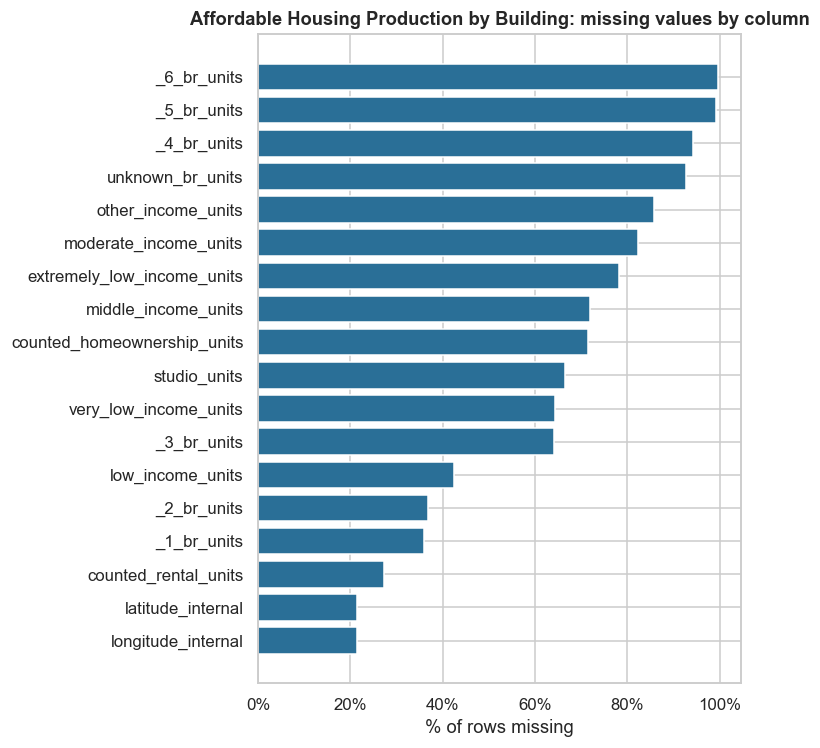

In [10]:
plot_missing(housing_raw, "Affordable Housing Production by Building", HOUSING_COLOR)

**What the missing-value profile tells us.** Three distinct problems, with three
different causes, which is why they need three different treatments:

1. `building_completion_date` is missing for projects that are financed but not
   finished. That is *informative* missingness, not an error.
2. `latitude`/`longitude`/`postcode` are missing for a block of rows whose
   `project_name` is literally `CONFIDENTIAL` — HPD suppresses the location of
   certain projects (typically supportive or domestic-violence housing). These
   rows cannot be placed in a ZIP code and so cannot enter a ZIP-level analysis.
3. Everything else is sparse and incidental.

We quantify (2) before deciding what to do about it.

In [11]:
confidential_mask = (
    housing_raw["project_name"].astype("string").str.upper().str.contains("CONFIDENTIAL", na=False)
)
print(f"rows flagged CONFIDENTIAL : {confidential_mask.sum():,} "
      f"({100 * confidential_mask.mean():.2f}% of rows)")
print(f"   ... of which missing postcode : {housing_raw.loc[confidential_mask, 'postcode'].isna().sum():,}")
print(f"   ... units they represent      : {housing_raw.loc[confidential_mask, 'total_units'].sum():,.0f}")
print()
print(f"rows missing postcode (any reason): {housing_raw['postcode'].isna().sum():,} "
      f"({100 * housing_raw['postcode'].isna().mean():.2f}%)")

rows flagged CONFIDENTIAL : 1,949 (20.41% of rows)
   ... of which missing postcode : 1,949
   ... units they represent      : 2,806

rows missing postcode (any reason): 1,958 (20.50%)


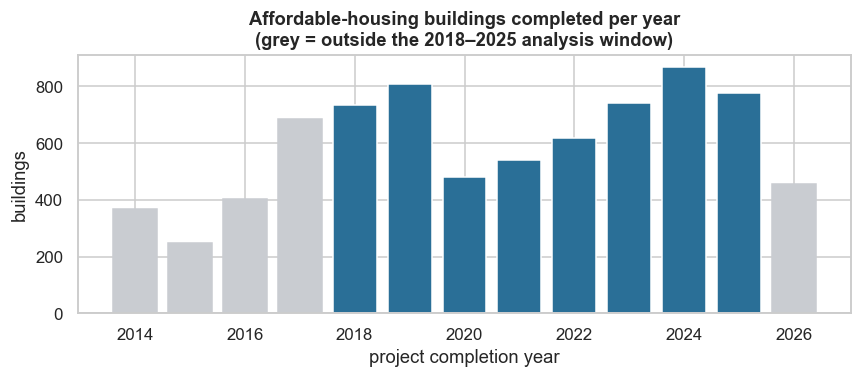

rows with no project_completion_date at all: 1,819 (19.0%)


In [12]:
# Completions per year, the backbone of every time series we will build.
completion_year = pd.to_datetime(
    housing_raw["project_completion_date"], errors="coerce"
).dt.year

fig, ax = plt.subplots(figsize=(8, 3.6))
counts = completion_year.value_counts().sort_index()
bars = ax.bar(counts.index.astype(int), counts.to_numpy(), color=HOUSING_COLOR)
for year, bar in zip(counts.index.astype(int), bars):
    if year < YEAR_MIN or year > YEAR_MAX:
        bar.set_color("#c9ccd1")  # grey out what the analysis window excludes
ax.set_title("Affordable-housing buildings completed per year\n(grey = outside the 2018–2025 analysis window)")
ax.set_xlabel("project completion year")
ax.set_ylabel("buildings")
thousands(ax)
plt.show()

print(f"rows with no project_completion_date at all: "
      f"{completion_year.isna().sum():,} ({100 * completion_year.isna().mean():.1f}%)")

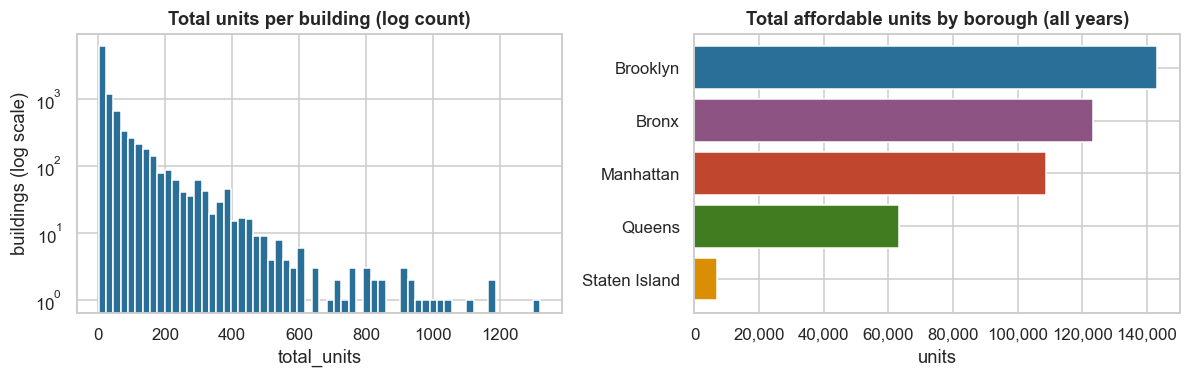

Tukey fence on total_units: [-60, 108]
buildings above the upper fence: 1,171
largest building in the data   : 1,320 units


In [13]:
# Unit-size distribution. Log x-axis because a handful of towers dominate.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

positive_units = housing_raw.loc[housing_raw["total_units"] > 0, "total_units"]
axes[0].hist(positive_units, bins=60, color=HOUSING_COLOR)
axes[0].set_yscale("log")
axes[0].set_title("Total units per building (log count)")
axes[0].set_xlabel("total_units")
axes[0].set_ylabel("buildings (log scale)")

by_boro = housing_raw.groupby("borough")["total_units"].sum().sort_values()
axes[1].barh(by_boro.index, by_boro.to_numpy(),
             color=[BOROUGH_COLORS.get(str(b).upper(), NEUTRAL_COLOR) for b in by_boro.index])
axes[1].set_title("Total affordable units by borough (all years)")
axes[1].set_xlabel("units")
thousands(axes[1], axis="x")
plt.show()

lo, hi = iqr_bounds(positive_units)
print(f"Tukey fence on total_units: [{lo:,.0f}, {hi:,.0f}]")
print(f"buildings above the upper fence: {(positive_units > hi).sum():,}")
print(f"largest building in the data   : {positive_units.max():,.0f} units")

**On those "outliers".** The Tukey fence sits at 108 units and flags **1,171
buildings** as high outliers; the largest building in the data has **1,320
units**. These are **not** data errors — large affordable developments genuinely
exist, and deleting them would delete most of the affordable housing in the
dataset, which is precisely what we are trying to measure. We therefore **keep**
them and handle their leverage statistically instead: we log-scale axes where
the skew hurts readability, and we use medians and quartiles rather than means
wherever a single large project could swing a borough's number.

The outlier rule we *do* apply is a domain rule, not a statistical one:
`total_units <= 0` is impossible for a building that was produced.

## 2.2 Crashes: descriptive statistics

In [14]:
injury_cols = [
    "number_of_persons_injured", "number_of_persons_killed",
    "number_of_pedestrians_injured", "number_of_pedestrians_killed",
    "number_of_cyclist_injured", "number_of_cyclist_killed",
    "number_of_motorist_injured", "number_of_motorist_killed",
]
crashes_raw[injury_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
number_of_persons_injured,"1,043,897.000",0.412,0.768,0.000,0.000,0.000,1.000,40.000
number_of_persons_killed,"1,043,889.000",0.002,0.047,0.000,0.000,0.000,0.000,5.000
number_of_pedestrians_injured,"1,043,903.000",0.070,0.268,0.000,0.000,0.000,0.000,19.000
number_of_pedestrians_killed,"1,043,903.000",0.001,0.031,0.000,0.000,0.000,0.000,4.000
number_of_cyclist_injured,"1,043,903.000",0.038,0.196,0.000,0.000,0.000,0.000,3.000
number_of_cyclist_killed,"1,043,903.000",0.000,0.013,0.000,0.000,0.000,0.000,1.000
number_of_motorist_injured,"1,043,903.000",0.292,0.733,0.000,0.000,0.000,0.000,40.000
number_of_motorist_killed,"1,043,903.000",0.001,0.031,0.000,0.000,0.000,0.000,5.000


In [15]:
show_missing(crashes_raw, "crashes_raw")

crashes_raw: 1,043,903 rows x 29 columns | 20 columns contain missing values


,n_missing,pct_missing
vehicle_type_code_5,1038019,99.436
contributing_factor_vehicle_5,1037789,99.414
vehicle_type_code_4,1023896,98.083
contributing_factor_vehicle_4,1022881,97.986
vehicle_type_code_3,964131,92.358
contributing_factor_vehicle_3,958959,91.863
off_street_name,771430,73.899
cross_street_name,526805,50.465
zip_code,343480,32.903
borough,333457,31.943


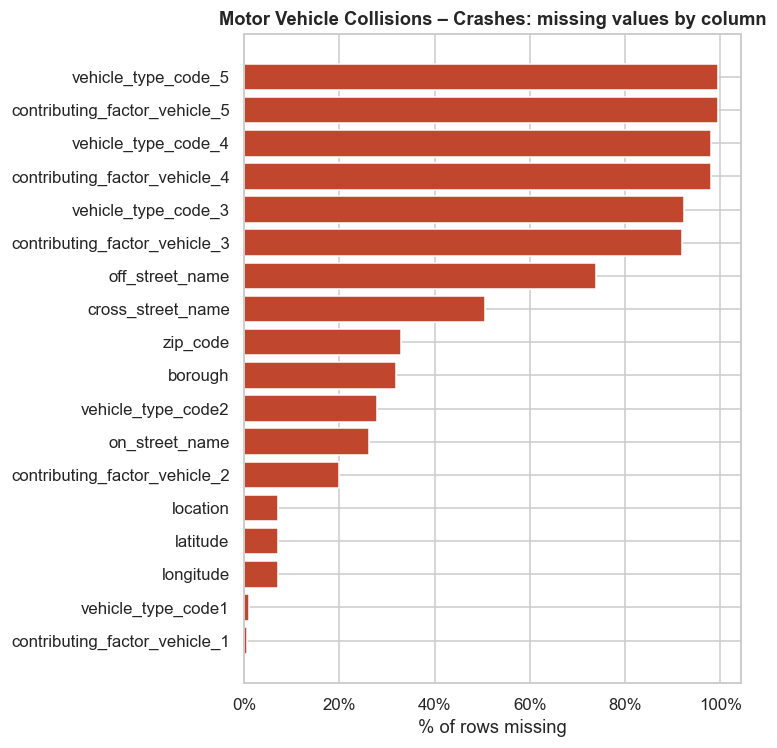

In [16]:
plot_missing(crashes_raw, "Motor Vehicle Collisions – Crashes", CRASH_COLOR)

**The single most important fact in this notebook.** Roughly a third of crash
records have **no ZIP code and no borough**. That is not random: NYPD geocodes a
collision to a ZIP when it happens on the local street grid, and frequently does
not when it happens on a highway, bridge, tunnel or parkway — places that sit
*between* ZIP codes rather than inside one.

Because our entire integration is keyed on ZIP, those rows cannot be used. We
quantify the loss precisely and we state the resulting bias openly, both here
and in the limitations section: **this analysis under-counts highway crashes,
and therefore under-counts high-speed, high-severity motorist collisions.**
Since our headline measure is pedestrian and cyclist injury — which is
overwhelmingly a surface-street phenomenon — the bias works against the crashes
we care least about, but it is a real limit and we do not hide it.

In [17]:
no_zip = crashes_raw["zip_code"].isna()
print(f"crash rows with no zip_code : {no_zip.sum():,} ({100 * no_zip.mean():.1f}%)")
print(f"crash rows with no borough  : {crashes_raw['borough'].isna().sum():,} "
      f"({100 * crashes_raw['borough'].isna().mean():.1f}%)")
print()

comparison = pd.DataFrame({
    "has ZIP": crashes_raw.loc[~no_zip, injury_cols].mean(),
    "no ZIP": crashes_raw.loc[no_zip, injury_cols].mean(),
})
comparison["ratio (no ZIP / has ZIP)"] = comparison["no ZIP"] / comparison["has ZIP"]
print("Mean casualties per crash, by whether the record is geocoded to a ZIP:")
comparison

crash rows with no zip_code : 343,480 (32.9%)
crash rows with no borough  : 333,457 (31.9%)

Mean casualties per crash, by whether the record is geocoded to a ZIP:


,has ZIP,no ZIP,ratio (no ZIP / has ZIP)
number_of_persons_injured,0.390,0.455,1.168
number_of_persons_killed,0.002,0.003,1.579
number_of_pedestrians_injured,0.081,0.047,0.583
number_of_pedestrians_killed,0.001,0.001,1.178
number_of_cyclist_injured,0.044,0.028,0.640
number_of_cyclist_killed,0.000,0.000,0.916
number_of_motorist_injured,0.252,0.373,1.480
number_of_motorist_killed,0.001,0.001,2.481


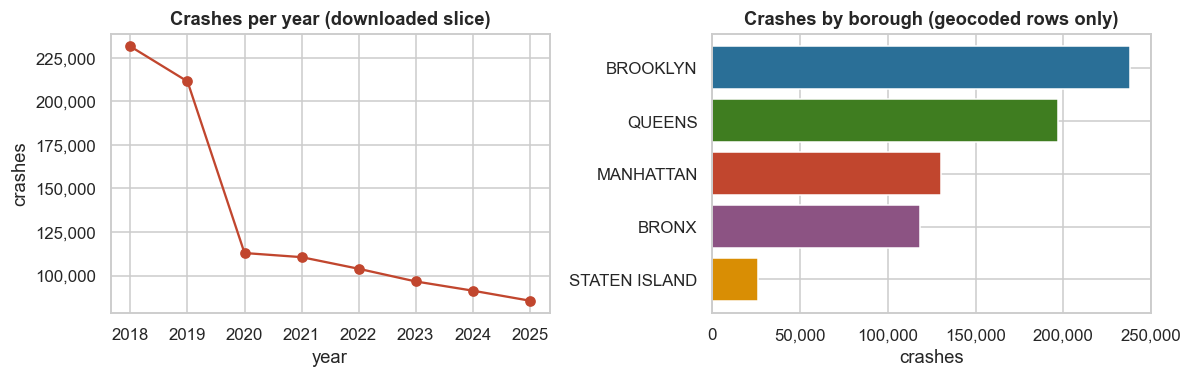

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))

crash_year = pd.to_datetime(crashes_raw["crash_date"], errors="coerce").dt.year
per_year = crash_year.value_counts().sort_index()
axes[0].plot(per_year.index.astype(int), per_year.to_numpy(), marker="o", color=CRASH_COLOR)
axes[0].set_title("Crashes per year (downloaded slice)")
axes[0].set_xlabel("year")
axes[0].set_ylabel("crashes")
thousands(axes[0])

boro_counts = crashes_raw["borough"].value_counts()
axes[1].barh(boro_counts.index[::-1], boro_counts.to_numpy()[::-1],
             color=[BOROUGH_COLORS.get(str(b).upper(), NEUTRAL_COLOR)
                    for b in boro_counts.index[::-1]])
axes[1].set_title("Crashes by borough (geocoded rows only)")
axes[1].set_xlabel("crashes")
thousands(axes[1], axis="x")
plt.show()

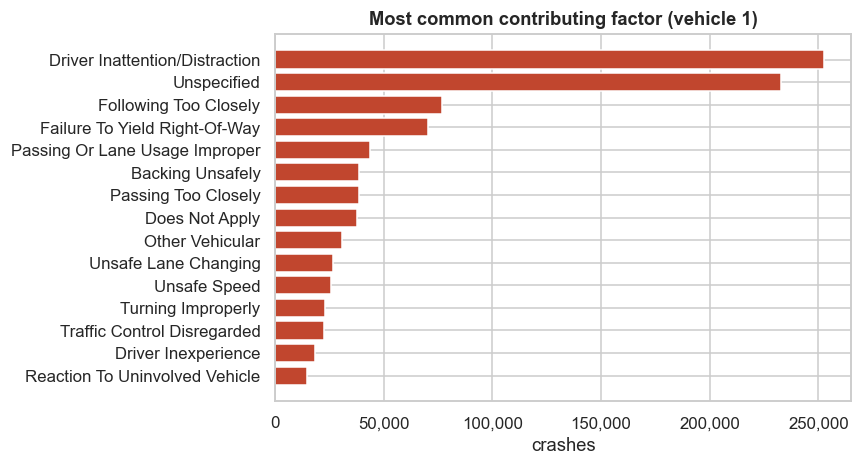

In [19]:
# Top contributing factors — we will use these in research question 9.
factor_counts = (
    crashes_raw["contributing_factor_vehicle_1"]
    .astype("string").str.strip().str.title()
    .value_counts().head(15)
)
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(factor_counts.index[::-1], factor_counts.to_numpy()[::-1], color=CRASH_COLOR)
ax.set_title("Most common contributing factor (vehicle 1)")
ax.set_xlabel("crashes")
thousands(ax, axis="x")
plt.show()

In [20]:
# Coordinate sanity: NYC sits inside roughly lat 40.47-40.93, lon -74.30 to -73.68.
coords = crashes_raw[["latitude", "longitude"]].dropna()
zero_island = ((coords["latitude"] == 0) | (coords["longitude"] == 0)).sum()
outside = (
    ~coords["latitude"].between(40.4, 41.0) | ~coords["longitude"].between(-74.35, -73.6)
).sum()
print(f"crash rows with a coordinate pair : {len(coords):,}")
print(f"   exactly (0, 0) or a zero axis  : {zero_island:,}")
print(f"   outside the NYC bounding box   : {outside:,}")

h_coords = housing_raw[["latitude", "longitude"]].dropna()
h_outside = (
    ~h_coords["latitude"].between(40.4, 41.0) | ~h_coords["longitude"].between(-74.35, -73.6)
).sum()
print(f"\nhousing rows with a coordinate pair : {len(h_coords):,}")
print(f"   outside the NYC bounding box     : {h_outside:,}")

crash rows with a coordinate pair : 969,669
   exactly (0, 0) or a zero axis  : 6,243
   outside the NYC bounding box   : 6,286

housing rows with a coordinate pair : 7,593
   outside the NYC bounding box     : 0


---
# 3. Pre-integration cleaning

Each subsection states **what** is wrong, **what we do**, and **why that choice
rather than the alternative**.

## 3.1 Housing

| # | Problem | Decision | Why not the alternative |
|---|---|---|---|
| 1 | `postcode` is a float (`10001.0`) | cast to a 5-character zero-padded **string** | ZIP is a label, not a quantity; leaving it numeric breaks the join against the crash side and lets pandas average it |
| 2 | `borough` casing/whitespace varies | upper-case and strip | a join on `"Brooklyn"` vs `"BROOKLYN"` silently drops rows |
| 3 | `building_completion_date` missing for unfinished projects | use `building_completion_date`, **fall back** to `project_completion_date`, then drop what remains undated | imputing a date outright would invent facts, so the fallback uses a real published date from the same row. In the event it rescues only 13 rows and 1,653 remain undated — these are financed-but-unbuilt projects, and a building that does not exist yet has no street to open onto, so dropping them is correct rather than merely convenient |
| 4 | `CONFIDENTIAL` projects have no ZIP or coordinates | **drop**, and report the count and units lost | they cannot be assigned to any ZIP, so no imputation is defensible. Assigning them to a borough-modal ZIP would fabricate geography |
| 5 | `total_units <= 0` | drop (domain rule) | a produced building with zero units is a data error, not a small building |
| 6 | large towers flagged by the Tukey fence | **keep**; use medians/quartiles and log scales | they are the real subject of the study; removing them removes the phenomenon |
| 7 | duplicate `building_id` | drop duplicates, keeping the most recently completed record | the same building can be restated across reporting cycles |

In [21]:
def standardise_zip(series):
    """ZIP as a 5-character string. Anything that is not a plausible NYC ZIP -> NA.

    NYC ZIP codes run from 10001 to 11697. Values outside that range are typos
    or out-of-city records and are set to missing rather than silently kept.
    """
    cleaned = (
        pd.to_numeric(series, errors="coerce")
        .astype("Float64").round(0).astype("Int64")
    )
    cleaned = cleaned.where(cleaned.between(10001, 11697))
    return cleaned.astype("string").str.zfill(5)


def standardise_borough(series):
    """Upper-case, trimmed, internal whitespace collapsed."""
    return (
        series.astype("string").str.strip().str.upper().str.replace(r"\s+", " ", regex=True)
    )

In [22]:
housing = housing_raw.copy()
audit = []  # running log of every row we remove, printed at the end


def drop_rows(df, mask, reason):
    """Drop `mask` rows from df, recording how many went and why."""
    n = int(mask.sum())
    audit.append({"step": reason, "rows_removed": n, "rows_left": len(df) - n})
    return df.loc[~mask].copy()


# --- 1 & 2: format standardisation -----------------------------------------
housing["zip_code"] = standardise_zip(housing["postcode"])
housing["borough"] = standardise_borough(housing["borough"])

# --- 3: one trustworthy completion date per building ------------------------
building_date = pd.to_datetime(housing["building_completion_date"], errors="coerce")
project_date = pd.to_datetime(housing["project_completion_date"], errors="coerce")
housing["completion_date"] = building_date.fillna(project_date)
housing["completion_source"] = np.where(
    building_date.notna(), "building_completion_date",
    np.where(project_date.notna(), "project_completion_date (fallback)", "none"),
)
print(housing["completion_source"].value_counts().to_string())

completion_source
building_completion_date              7885
none                                  1653
project_completion_date (fallback)      13


In [23]:
# --- 4: confidential / unplaceable rows -------------------------------------
confidential = (
    housing["project_name"].astype("string").str.upper().str.contains("CONFIDENTIAL", na=False)
)
units_lost = housing.loc[confidential, "total_units"].sum()
housing = drop_rows(housing, confidential, "CONFIDENTIAL projects (no usable geography)")
print(f"dropped {int(units_lost):,} units attached to confidential projects")

housing = drop_rows(housing, housing["zip_code"].isna(), "no valid NYC ZIP code")
housing = drop_rows(housing, housing["completion_date"].isna(), "no completion date of any kind")

# --- 5: domain outlier rule --------------------------------------------------
housing = drop_rows(housing, housing["total_units"].fillna(0) <= 0, "total_units <= 0")

# --- coordinates outside NYC -> set to NA rather than dropping the row -------
bad_coords = ~(
    housing["latitude"].between(40.4, 41.0) & housing["longitude"].between(-74.35, -73.6)
)
n_bad = int((bad_coords & housing["latitude"].notna()).sum())
housing.loc[bad_coords, ["latitude", "longitude"]] = np.nan
print(f"blanked {n_bad:,} out-of-range coordinate pairs (row kept: ZIP is still valid)")

dropped 2,806 units attached to confidential projects
blanked 0 out-of-range coordinate pairs (row kept: ZIP is still valid)


Note the asymmetry in the last step. A bad **coordinate** only costs us a dot on
a map, so we null the coordinate and keep the row, because its ZIP, units and
date are all still good. A bad **ZIP** costs us the join key itself, so the row
has to go. Cleaning decisions should be proportional to what the defect actually
destroys.

In [24]:
# --- 7: duplicates -----------------------------------------------------------
dupe_ids = housing["building_id"].duplicated(keep=False)
print(f"rows sharing a building_id: {int(dupe_ids.sum()):,}")

before = len(housing)
housing = (
    housing.sort_values("completion_date")
    .drop_duplicates(subset="building_id", keep="last")
    .reset_index(drop=True)
)
audit.append({"step": "duplicate building_id (kept latest)",
              "rows_removed": before - len(housing), "rows_left": len(housing)})

# --- derived fields used downstream -----------------------------------------
housing["year"] = housing["completion_date"].dt.year
housing["units_deep_affordable"] = (
    housing["extremely_low_income_units"].fillna(0) + housing["very_low_income_units"].fillna(0)
)
housing["units_3br_plus"] = (
    housing["_3_br_units"].fillna(0) + housing["_4_br_units"].fillna(0)
    + housing["_5_br_units"].fillna(0) + housing["_6_br_units"].fillna(0)
)

# --- restrict to the analysis window ----------------------------------------
housing = drop_rows(
    housing, ~housing["year"].between(YEAR_MIN, YEAR_MAX),
    f"completion outside {YEAR_MIN}-{YEAR_MAX}",
)

print()
print(pd.DataFrame(audit).to_string(index=False))
print(f"\nhousing cleaned: {len(housing):,} rows "
      f"({100 * len(housing) / len(housing_raw):.1f}% of raw), "
      f"{housing['total_units'].sum():,.0f} units")

rows sharing a building_id: 155

                                       step  rows_removed  rows_left
CONFIDENTIAL projects (no usable geography)          1949       7602
                      no valid NYC ZIP code             9       7593
             no completion date of any kind          1575       6018
                           total_units <= 0             0       6018
        duplicate building_id (kept latest)            78       5940
               completion outside 2018-2025          1548       4392

housing cleaned: 4,392 rows (46.0% of raw), 249,178 units


## 3.2 Crashes

| # | Problem | Decision | Why not the alternative |
|---|---|---|---|
| 1 | ~33% of rows have no `zip_code` | **drop**, and quantify the bias explicitly | ZIP is the join key; there is nothing to impute from. Borough-level imputation would smear highway crashes across surface-street ZIPs and corrupt the very measure we report |
| 2 | `zip_code` arrives as float/text with stray values | same `standardise_zip` as the housing side | the two sides must be formatted by *one* function or the join will quietly fail |
| 3 | `borough` missing but ZIP present | back-fill borough from the ZIP's modal borough | the mapping ZIP→borough is near-deterministic in NYC, so this recovers rows at negligible risk |
| 4 | coordinates of exactly (0, 0) | set to NA | a crash in the Gulf of Guinea is a null, not a location |
| 5 | injury counts are missing or absurd | fill NA with 0; flag >50 casualties for review | a blank casualty field on a police report means "none"; a 50-casualty crash is a bus incident and genuinely possible, so we inspect rather than delete |
| 6 | duplicate `collision_id` | drop | an artefact of paged downloading |
| 7 | contributing factors inconsistently cased, `"Unspecified"` used as a null | title-case; treat `Unspecified` as its own honest category | collapsing it into NA would overstate how much we know about causes |

In [25]:
crashes = crashes_raw.copy()
crash_audit = []


def drop_crash_rows(df, mask, reason):
    n = int(mask.sum())
    crash_audit.append({"step": reason, "rows_removed": n, "rows_left": len(df) - n})
    return df.loc[~mask].copy()


# --- 6: duplicates from paged download --------------------------------------
crashes = drop_crash_rows(crashes, crashes["collision_id"].duplicated(), "duplicate collision_id")

# --- 2: ZIP formatting, shared function with the housing side ----------------
crashes["zip_code"] = standardise_zip(crashes["zip_code"])
crashes["borough"] = standardise_borough(crashes["borough"])

# --- 1: rows with no join key -----------------------------------------------
crashes = drop_crash_rows(crashes, crashes["zip_code"].isna(), "no valid NYC ZIP code (join key)")

# --- 3: recover borough from ZIP where possible ------------------------------
zip_to_boro = (
    crashes.dropna(subset=["borough"])
    .groupby("zip_code")["borough"]
    .agg(lambda s: s.mode().iat[0])
)
missing_boro = crashes["borough"].isna()
crashes.loc[missing_boro, "borough"] = crashes.loc[missing_boro, "zip_code"].map(zip_to_boro)
print(f"borough back-filled from ZIP for {int(missing_boro.sum()):,} rows; "
      f"{int(crashes['borough'].isna().sum()):,} still unknown")
crashes = drop_crash_rows(crashes, crashes["borough"].isna(), "borough unrecoverable")

borough back-filled from ZIP for 0 rows; 0 still unknown


In [26]:
# --- 4: impossible coordinates ------------------------------------------------
zero_coord = (crashes["latitude"] == 0) | (crashes["longitude"] == 0)
out_of_box = ~(
    crashes["latitude"].between(40.4, 41.0) & crashes["longitude"].between(-74.35, -73.6)
)
bad = (zero_coord | out_of_box) & crashes["latitude"].notna()
crashes.loc[bad, ["latitude", "longitude"]] = np.nan
print(f"blanked {int(bad.sum()):,} impossible coordinate pairs (rows kept — ZIP is intact)")

# --- 5: casualty columns ------------------------------------------------------
for col in injury_cols:
    crashes[col] = pd.to_numeric(crashes[col], errors="coerce").fillna(0).astype("int32")

injured = crashes["number_of_persons_injured"]
lo, hi = iqr_bounds(injured)
print(f"Tukey fence on persons_injured : [{lo:.1f}, {hi:.1f}]")
print(f"crashes above that fence       : {int((injured > hi).sum()):,} "
      f"({100 * (injured > hi).mean():.1f}% of all crashes)")
print(f"crashes with >20 people injured: {int((injured > 20).sum())}")
print(f"crashes with >50 people injured: {int((injured > 50).sum())}")
print(f"worst single crash             : {int(injured.max())} injured")

blanked 4,948 impossible coordinate pairs (rows kept — ZIP is intact)
Tukey fence on persons_injured : [-1.5, 2.5]
crashes above that fence       : 13,277 (1.9% of all crashes)
crashes with >20 people injured: 4
crashes with >50 people injured: 0
worst single crash             : 34 injured


**This is where a blind outlier rule would have done real damage.** The Tukey
fence on `persons_injured` sits at **2.5**, because three quarters of crashes
injure nobody at all. Applying it mechanically would classify *every crash that
hurt three or more people* as an outlier and delete it — that is, it would
delete precisely the severe collisions a street-safety analysis exists to
measure.

We therefore apply **no statistical outlier rule to the casualty columns**. The
domain check we do run — a scan for implausibly large counts — returns **zero**
crashes above 50 injured, and only 4 above 20, with a worst case of 34. Nothing
here is a data-entry error, so nothing is removed.

The general point is worth stating once: *an outlier test is a question, not an
instruction.* It told us where to look; the domain decided what to do.

In [27]:
# --- 7: contributing factors --------------------------------------------------
for col in ["contributing_factor_vehicle_1", "contributing_factor_vehicle_2"]:
    crashes[col] = (
        crashes[col].astype("string").str.strip().str.title().replace({"": pd.NA})
        .fillna("Unspecified")
    )

# --- derived fields ------------------------------------------------------------
crashes["crash_dt"] = pd.to_datetime(crashes["crash_date"], errors="coerce")
crashes = drop_crash_rows(crashes, crashes["crash_dt"].isna(), "unparseable crash_date")
crashes["year"] = crashes["crash_dt"].dt.year
crashes = drop_crash_rows(
    crashes, ~crashes["year"].between(YEAR_MIN, YEAR_MAX), f"outside {YEAR_MIN}-{YEAR_MAX}"
)

# Vulnerable road users = pedestrians + cyclists. This is the project's core metric.
crashes["vru_injured"] = (
    crashes["number_of_pedestrians_injured"] + crashes["number_of_cyclist_injured"]
)
crashes["vru_killed"] = (
    crashes["number_of_pedestrians_killed"] + crashes["number_of_cyclist_killed"]
)

print()
print(pd.DataFrame(crash_audit).to_string(index=False))
print(f"\ncrashes cleaned: {len(crashes):,} rows "
      f"({100 * len(crashes) / len(crashes_raw):.1f}% of the downloaded slice)")


                            step  rows_removed  rows_left
          duplicate collision_id             0    1043903
no valid NYC ZIP code (join key)        343941     699962
           borough unrecoverable             0     699962
          unparseable crash_date             0     699962
               outside 2018-2025             0     699962

crashes cleaned: 699,962 rows (67.1% of the downloaded slice)


---
# 4. Integration

## 4.1 Choosing the key

The two datasets have **no shared entity**. A building is not a collision, and
no identifier links them. What they share is *where* and *when*. Four candidate
keys, and why we landed where we did:

| Candidate | Verdict |
|---|---|
| **Borough × year** | Only 5 boroughs. Far too coarse — it would average Brownsville together with Brooklyn Heights and show nothing. |
| **Census tract × year** | Ideal in principle, but the crash dataset has no tract column. Deriving it needs a point-in-polygon join against a TIGER shapefile, which is outside this milestone's scope and would silently drop the third of crashes that already lack coordinates. |
| **Spatial buffer around each building** | The most precise option, and the natural follow-up for Milestone 2. It needs a projected CRS and a spatial index, and it inherits the coordinate-missingness problem above. |
| **ZIP code × year** ✅ | Present and populated on both sides, ~180 NYC ZIPs gives real within-borough variation, and a year is long enough that a single ZIP accumulates a stable number of crashes. |

**Granularity justification.** A ZIP code in New York holds on the order of
20,000–100,000 people — close to a neighbourhood, which is the scale at which
both housing siting and street design are actually decided. A year smooths the
strong seasonality in crashes while still giving us eight observations per ZIP.
In the event this yields **228 ZIP codes and 1,677 ZIP-year cells**, enough to
look at distributions rather than anecdotes.

**We deliberately do not perform a row-level join.** Matching an individual
crash to an individual building would imply a relationship the data cannot
support. Both sides are aggregated first, then joined.

## 4.2 Aggregating each side

In [28]:
# --- housing side: one row per ZIP-year -------------------------------------
housing_zip_year = (
    housing.groupby(["zip_code", "year"], as_index=False)
    .agg(
        borough=("borough", lambda s: s.mode().iat[0]),
        buildings_completed=("building_id", "nunique"),
        units_total=("total_units", "sum"),
        units_counted=("all_counted_units", "sum"),
        units_extremely_low=("extremely_low_income_units", "sum"),
        units_very_low=("very_low_income_units", "sum"),
        units_low=("low_income_units", "sum"),
        units_moderate=("moderate_income_units", "sum"),
        units_middle=("middle_income_units", "sum"),
        units_deep_affordable=("units_deep_affordable", "sum"),
        units_studio=("studio_units", "sum"),
        units_1br=("_1_br_units", "sum"),
        units_2br=("_2_br_units", "sum"),
        units_3br_plus=("units_3br_plus", "sum"),
        housing_lat=("latitude", "mean"),
        housing_lon=("longitude", "mean"),
    )
)
print(f"housing aggregated: {len(housing_zip_year):,} ZIP-year cells "
      f"across {housing_zip_year['zip_code'].nunique()} ZIP codes")
housing_zip_year.head()

housing aggregated: 721 ZIP-year cells across 144 ZIP codes


,zip_code,year,borough,buildings_completed,units_total,units_counted,units_extremely_low,units_very_low,units_low,units_moderate,units_middle,units_deep_affordable,units_studio,units_1br,units_2br,units_3br_plus,housing_lat,housing_lon
0,10001,2018,MANHATTAN,2,939,194.000,0.000,6.000,188.000,0.000,0.000,6.000,58.000,107.000,27.000,2.000,40.750,-73.996
1,10001,2019,MANHATTAN,1,223,45.000,0.000,0.000,45.000,0.000,0.000,0.000,14.000,26.000,5.000,0.000,40.749,-73.987
2,10001,2020,MANHATTAN,2,92,54.000,0.000,0.000,46.000,0.000,8.000,0.000,42.000,6.000,4.000,2.000,40.748,-73.994
3,10001,2021,MANHATTAN,1,106,106.000,0.000,0.000,106.000,0.000,0.000,0.000,24.000,29.000,53.000,0.000,40.753,-74.003
4,10001,2023,MANHATTAN,2,1418,378.000,0.000,94.000,238.000,46.000,0.000,94.000,95.000,234.000,48.000,1.000,40.750,-73.999


In [29]:
# --- crash side: one row per ZIP-year ---------------------------------------
crash_zip_year = (
    crashes.groupby(["zip_code", "year"], as_index=False)
    .agg(
        borough=("borough", lambda s: s.mode().iat[0]),
        crashes=("collision_id", "nunique"),
        persons_injured=("number_of_persons_injured", "sum"),
        persons_killed=("number_of_persons_killed", "sum"),
        ped_injured=("number_of_pedestrians_injured", "sum"),
        ped_killed=("number_of_pedestrians_killed", "sum"),
        cyc_injured=("number_of_cyclist_injured", "sum"),
        cyc_killed=("number_of_cyclist_killed", "sum"),
        mot_injured=("number_of_motorist_injured", "sum"),
        mot_killed=("number_of_motorist_killed", "sum"),
        vru_injured=("vru_injured", "sum"),
        vru_killed=("vru_killed", "sum"),
        crash_lat=("latitude", "mean"),
        crash_lon=("longitude", "mean"),
    )
)
print(f"crashes aggregated: {len(crash_zip_year):,} ZIP-year cells "
      f"across {crash_zip_year['zip_code'].nunique()} ZIP codes")
crash_zip_year.head()

crashes aggregated: 1,677 ZIP-year cells across 228 ZIP codes


,zip_code,year,borough,crashes,persons_injured,persons_killed,ped_injured,ped_killed,cyc_injured,cyc_killed,mot_injured,mot_killed,vru_injured,vru_killed,crash_lat,crash_lon
0,10001,2018,MANHATTAN,1715,209,0,74,0,38,0,97,0,112,0,40.750,-73.994
1,10001,2019,MANHATTAN,1401,187,0,68,0,35,0,84,0,103,0,40.750,-73.995
2,10001,2020,MANHATTAN,423,134,2,45,1,34,0,55,1,79,1,40.749,-73.995
3,10001,2021,MANHATTAN,480,196,1,50,1,52,0,89,0,102,1,40.750,-73.995
4,10001,2022,MANHATTAN,517,198,1,77,1,46,0,65,0,123,1,40.750,-73.996


## 4.3 Choosing the join type

This matters more than it looks. The three options give three different studies:

* **Inner join** — only ZIP-years that both built housing *and* had crashes.
  This silently deletes every ZIP that built nothing, which is exactly the
  comparison group we need. Rejected.
* **Right/left on housing** — same problem in reverse.
* **Outer join on the crash side as the spine** ✅ — every ZIP-year with any
  street activity is present; ZIP-years with no affordable completions get
  **zero** units, which is a true statement about them, not a missing value.

So the crash table is the spine, and housing is merged onto it. A ZIP-year that
built nothing is a real observation of "built nothing", and section 5 converts
its NaNs into honest zeros.

In [30]:
merged = crash_zip_year.merge(
    housing_zip_year.drop(columns=["borough"]),  # borough comes from the spine
    on=["zip_code", "year"],
    how="outer",
    indicator=True,
    validate="one_to_one",   # fails loudly if either side is not unique per key
)

print(merged["_merge"].value_counts().rename({
    "both": "ZIP-year had crashes AND completions",
    "left_only": "crashes but no affordable completions",
    "right_only": "completions but no crash records",
}).to_string())
print(f"\nmerged: {len(merged):,} ZIP-year rows")

_merge
crashes but no affordable completions    956
ZIP-year had crashes AND completions     721
completions but no crash records           0

merged: 1,677 ZIP-year rows


---
# 5. Post-integration cleaning *(required)*

Joining created three new classes of problem. Each is handled explicitly.

### 5.1 Nulls created by the join

Two different nulls, two different meanings, two different treatments:

* **Housing columns null because the ZIP-year had no completions** → fill with
  **0**. "No affordable units were completed here that year" is a measurement,
  not a gap. Leaving these as NaN would drop exactly the comparison group that
  the whole analysis rests on.
* **Crash columns null because a ZIP-year had completions but no crash records**
  → these are mostly very small or non-residential ZIPs. A zero here would be a
  *claim* that no crash occurred, which we cannot support. We **drop** these
  rows from the analysis table and report how many.

### 5.2 Redundant and inconsistent columns

The merge left `borough` from the spine plus the `_merge` indicator, and both
sides contributed their own mean coordinates. We keep one borough column, keep
the crash centroid as the ZIP's map position (it is computed from far more
points and so is more stable), keep the housing centroid for plotting buildings,
and drop the indicator once it has been used.

### 5.3 Data type mismatches

Summed integer columns come back as float because of the join; ZIP must stay a
string; year must be an integer. Fixed below and asserted.

In [31]:
analysis = merged.copy()

HOUSING_NUMERIC = [c for c in analysis.columns
                   if c.startswith("units_") or c == "buildings_completed"]
CRASH_NUMERIC = ["crashes", "persons_injured", "persons_killed", "ped_injured",
                 "ped_killed", "cyc_injured", "cyc_killed", "mot_injured",
                 "mot_killed", "vru_injured", "vru_killed"]

# --- 5.1a housing nulls are real zeros --------------------------------------
before_null = analysis[HOUSING_NUMERIC].isna().sum().sum()
analysis[HOUSING_NUMERIC] = analysis[HOUSING_NUMERIC].fillna(0)
print(f"filled {before_null:,} housing cells with 0 "
      f"(= 'no affordable completions in this ZIP-year')")

# --- 5.1b crash nulls are NOT zeros -----------------------------------------
no_crash_record = analysis["crashes"].isna()
print(f"dropping {int(no_crash_record.sum()):,} ZIP-years that have completions "
      f"but no crash records at all")
analysis = analysis.loc[~no_crash_record].copy()

# --- 5.2 redundant columns ----------------------------------------------------
analysis = analysis.drop(columns=["_merge"])

# --- 5.3 dtypes ---------------------------------------------------------------
analysis["zip_code"] = analysis["zip_code"].astype("string")
analysis["year"] = analysis["year"].astype("int16")
analysis["borough"] = analysis["borough"].astype("string")
for col in HOUSING_NUMERIC + CRASH_NUMERIC:
    analysis[col] = pd.to_numeric(analysis[col]).round(0).astype("int32")

assert analysis["zip_code"].str.len().eq(5).all(), "ZIP codes must be 5 characters"
assert analysis.duplicated(subset=["zip_code", "year"]).sum() == 0, "key must be unique"
assert analysis[CRASH_NUMERIC].ge(0).all().all(), "counts cannot be negative"
print("\npost-integration assertions passed")
analysis.dtypes.to_frame("dtype").T

filled 12,428 housing cells with 0 (= 'no affordable completions in this ZIP-year')
dropping 0 ZIP-years that have completions but no crash records at all

post-integration assertions passed


,zip_code,year,borough,crashes,persons_injured,persons_killed,ped_injured,ped_killed,cyc_injured,cyc_killed,mot_injured,mot_killed,vru_injured,vru_killed,crash_lat,crash_lon,buildings_completed,units_total,units_counted,units_extremely_low,units_very_low,units_low,units_moderate,units_middle,units_deep_affordable,units_studio,units_1br,units_2br,units_3br_plus,housing_lat,housing_lon
dtype,string,int16,string,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,float64,float64,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,int32,float64,float64


In [32]:
# --- derived rates, built only after cleaning so the denominators are sound ---
def safe_ratio(numerator, denominator, scale=1.0):
    """Element-wise ratio that yields NaN (not inf) when the denominator is 0."""
    denom = denominator.replace(0, np.nan)
    return (numerator / denom) * scale


analysis["injuries_per_100_crashes"] = safe_ratio(
    analysis["persons_injured"], analysis["crashes"], 100
)
analysis["vru_injuries_per_100_crashes"] = safe_ratio(
    analysis["vru_injured"], analysis["crashes"], 100
)
analysis["vru_share_of_injuries"] = safe_ratio(
    analysis["vru_injured"], analysis["persons_injured"], 100
)
analysis["deaths_per_1k_crashes"] = safe_ratio(
    analysis["persons_killed"], analysis["crashes"], 1000
)
analysis["deep_affordable_share"] = safe_ratio(
    analysis["units_deep_affordable"], analysis["units_total"], 100
)
analysis["has_completions"] = analysis["units_total"] > 0

# One stable map position per ZIP: prefer the crash centroid (many more points).
analysis["map_lat"] = analysis["crash_lat"].fillna(analysis["housing_lat"])
analysis["map_lon"] = analysis["crash_lon"].fillna(analysis["housing_lon"])

print(f"final analysis table: {len(analysis):,} ZIP-year rows, "
      f"{analysis['zip_code'].nunique()} ZIP codes, "
      f"{analysis['year'].min()}-{analysis['year'].max()}")
print(f"ZIP-years with at least one affordable completion: "
      f"{int(analysis['has_completions'].sum()):,} "
      f"({100 * analysis['has_completions'].mean():.1f}%)")
analysis.head()

final analysis table: 1,677 ZIP-year rows, 228 ZIP codes, 2018-2025
ZIP-years with at least one affordable completion: 721 (43.0%)


,zip_code,year,borough,crashes,persons_injured,persons_killed,ped_injured,ped_killed,cyc_injured,cyc_killed,mot_injured,mot_killed,vru_injured,vru_killed,crash_lat,crash_lon,buildings_completed,units_total,units_counted,units_extremely_low,units_very_low,units_low,units_moderate,units_middle,units_deep_affordable,units_studio,units_1br,units_2br,units_3br_plus,housing_lat,housing_lon,injuries_per_100_crashes,vru_injuries_per_100_crashes,vru_share_of_injuries,deaths_per_1k_crashes,deep_affordable_share,has_completions,map_lat,map_lon
0,10001,2018,MANHATTAN,1715,209,0,74,0,38,0,97,0,112,0,40.750,-73.994,2,939,194,0,6,188,0,0,6,58,107,27,2,40.750,-73.996,12.187,6.531,53.589,0.000,0.639,True,40.750,-73.994
1,10001,2019,MANHATTAN,1401,187,0,68,0,35,0,84,0,103,0,40.750,-73.995,1,223,45,0,0,45,0,0,0,14,26,5,0,40.749,-73.987,13.348,7.352,55.080,0.000,0.000,True,40.750,-73.995
2,10001,2020,MANHATTAN,423,134,2,45,1,34,0,55,1,79,1,40.749,-73.995,2,92,54,0,0,46,0,8,0,42,6,4,2,40.748,-73.994,31.678,18.676,58.955,4.728,0.000,True,40.749,-73.995
3,10001,2021,MANHATTAN,480,196,1,50,1,52,0,89,0,102,1,40.750,-73.995,1,106,106,0,0,106,0,0,0,24,29,53,0,40.753,-74.003,40.833,21.250,52.041,2.083,0.000,True,40.750,-73.995
4,10001,2022,MANHATTAN,517,198,1,77,1,46,0,65,0,123,1,40.750,-73.996,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,38.298,23.791,62.121,1.934,NaN,False,40.750,-73.996


---
# 6. Validating the cleaning

Claiming the data is clean is not the same as showing it. Three checks.

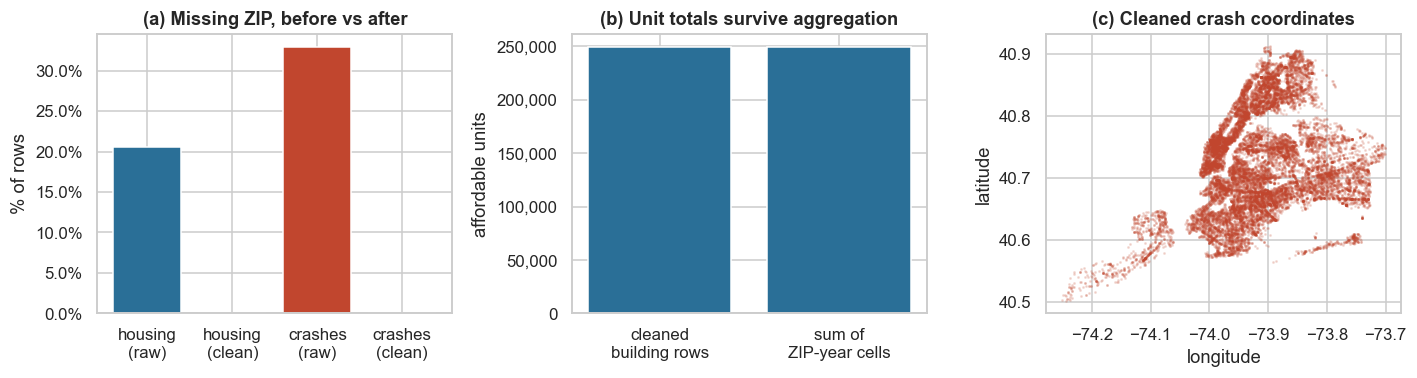

units in cleaned building table : 249,178
units summed over ZIP-year cells: 249,178
difference                      : 0 (ZIP-years dropped for having no crash record)


In [33]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

# (a) ZIP formatting is now identical on both sides.
axes[0].bar(
    ["housing\n(raw)", "housing\n(clean)", "crashes\n(raw)", "crashes\n(clean)"],
    [housing_raw["postcode"].isna().mean() * 100,
     housing["zip_code"].isna().mean() * 100,
     crashes_raw["zip_code"].isna().mean() * 100,
     crashes["zip_code"].isna().mean() * 100],
    color=[HOUSING_COLOR, HOUSING_COLOR, CRASH_COLOR, CRASH_COLOR],
)
axes[0].set_title("(a) Missing ZIP, before vs after")
axes[0].set_ylabel("% of rows")
axes[0].yaxis.set_major_formatter(mticker.PercentFormatter())

# (b) Totals are conserved: no units invented or lost in aggregation.
axes[1].bar(
    ["cleaned\nbuilding rows", "sum of\nZIP-year cells"],
    [housing["total_units"].sum(), analysis["units_total"].sum()],
    color=HOUSING_COLOR,
)
axes[1].set_title("(b) Unit totals survive aggregation")
axes[1].set_ylabel("affordable units")
thousands(axes[1])

# (c) Coordinates now all sit inside NYC.
sample = crashes[["latitude", "longitude"]].dropna().sample(
    min(20000, crashes["latitude"].notna().sum()), random_state=0
)
axes[2].scatter(sample["longitude"], sample["latitude"], s=1, alpha=0.15, color=CRASH_COLOR)
axes[2].set_title("(c) Cleaned crash coordinates")
axes[2].set_xlabel("longitude")
axes[2].set_ylabel("latitude")

plt.show()

units_clean = housing["total_units"].sum()
units_agg = analysis["units_total"].sum()
print(f"units in cleaned building table : {units_clean:,.0f}")
print(f"units summed over ZIP-year cells: {units_agg:,.0f}")
print(f"difference                      : {units_clean - units_agg:,.0f} "
      "(ZIP-years dropped for having no crash record)")

---
# 7. Research questions

Ten questions, one chart each. Who worked on what is listed in
`README.md`.

A note that applies to **all ten**: every relationship below is an
**association measured across ZIP-years**. None of it is causal. A ZIP code
where the city builds affordable housing differs from one where it does not in
a hundred ways we never observe — land price, zoning, existing density, street
width, political history. Section 8 says more.

## RQ1
### Do ZIP codes that build the most affordable housing have more dangerous streets for pedestrians and cyclists?

We rank ZIP-years by affordable units completed, split them into quartiles
(plus a separate "built nothing" group), and compare the share of all injuries
that fall on pedestrians and cyclists.

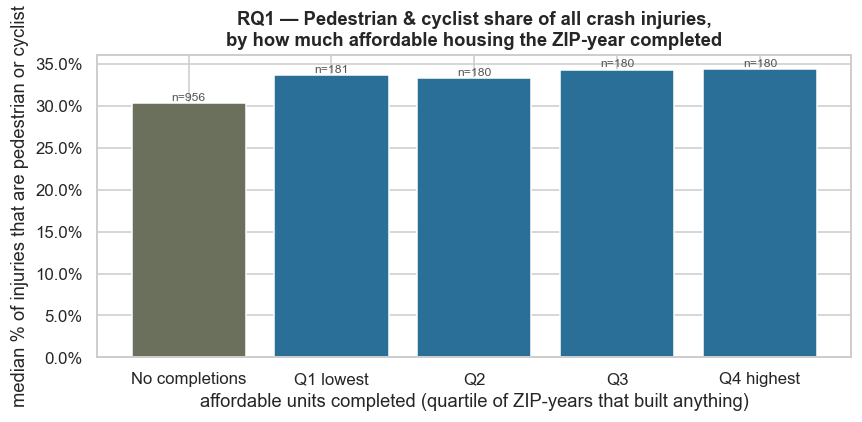

,dev_tier,vru_share,vru_rate,n
0,No completions,30.335,9.724,956
1,Q1 lowest,33.735,13.376,181
2,Q2,33.379,13.628,180
3,Q3,34.351,14.922,180
4,Q4 highest,34.416,14.620,180


In [34]:
def development_tier(df):
    """Label each ZIP-year by how much affordable housing it completed."""
    built = df["units_total"] > 0
    tier = pd.Series("No completions", index=df.index, dtype="object")
    if built.sum() > 4:
        quartiles = pd.qcut(
            df.loc[built, "units_total"], 4,
            labels=["Q1 lowest", "Q2", "Q3", "Q4 highest"],
        )
        tier.loc[built] = quartiles.astype(str)
    return pd.Categorical(
        tier, categories=["No completions", "Q1 lowest", "Q2", "Q3", "Q4 highest"], ordered=True
    )


analysis["dev_tier"] = development_tier(analysis)

rq1 = (
    analysis.groupby("dev_tier", observed=True)
    .agg(vru_share=("vru_share_of_injuries", "median"),
         vru_rate=("vru_injuries_per_100_crashes", "median"),
         n=("zip_code", "size"))
    .reset_index()
)

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(rq1["dev_tier"].astype(str), rq1["vru_share"],
              color=[NEUTRAL_COLOR] + [HOUSING_COLOR] * 4)
for bar, n in zip(bars, rq1["n"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
            f"n={n}", ha="center", fontsize=8, color="#555")
ax.set_title("RQ1 — Pedestrian & cyclist share of all crash injuries,\n"
             "by how much affordable housing the ZIP-year completed")
ax.set_xlabel("affordable units completed (quartile of ZIP-years that built anything)")
ax.set_ylabel("median % of injuries that are pedestrian or cyclist")
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
plt.show()

rq1

### What RQ1 shows

A clear gap, but not the shape we expected.

* ZIP-years that completed **no** affordable housing: median **9.7**
  pedestrian-and-cyclist injuries per 100 crashes (n = 956).
* ZIP-years that completed **any**: **13.4, 13.6, 14.9, 14.6** across the four
  quartiles (n ≈ 180 each).

So the difference is **binary, not a dose–response**. Building a lot is barely
different from building a little; *building at all* is what separates the
groups. A causal story in which construction makes streets more dangerous would
predict a rising gradient across Q1 → Q4, and there is none.

The more plausible reading is **composition**: 531 of the 956 no-completion
ZIP-years belong to 84 ZIP codes that never completed a single affordable unit
between 2018 and 2025. Those tend to be lower-density, more car-oriented parts
of the city where a larger share of crash injuries are motorists. The contrast
is largely *between different kinds of neighbourhood*, not between the same
neighbourhood before and after it builds. RQ3 tests that directly.

## RQ2
### Is that gap widening or closing over time?

Same two groups — ZIP-years in the top development quartile versus ZIP-years
that completed nothing — tracked year by year.

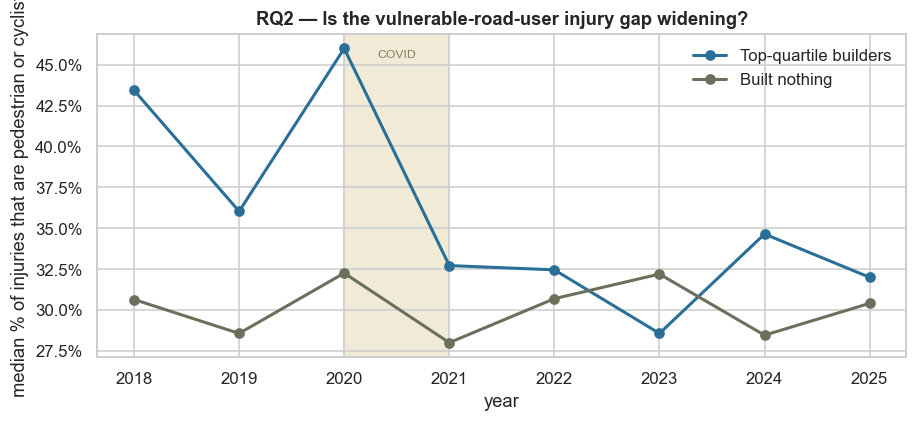

In [35]:
rq2 = (
    analysis.assign(
        group=np.where(analysis["dev_tier"].astype(str) == "Q4 highest", "Top-quartile builders",
                np.where(analysis["dev_tier"].astype(str) == "No completions", "Built nothing", "Other"))
    )
    .query("group != 'Other'")
    .groupby(["year", "group"], observed=True)["vru_share_of_injuries"]
    .median().reset_index()
)

fig, ax = plt.subplots(figsize=(8.5, 4))
for group, color in [("Top-quartile builders", HOUSING_COLOR), ("Built nothing", NEUTRAL_COLOR)]:
    sub = rq2[rq2["group"] == group]
    ax.plot(sub["year"], sub["vru_share_of_injuries"], marker="o", label=group, color=color, lw=2)
ax.axvspan(2020, 2021, color="#f0ead6", zorder=0)
ax.text(2020.5, ax.get_ylim()[1] * 0.98, "COVID", ha="center", va="top", fontsize=8, color="#8a7f5c")
ax.set_title("RQ2 — Is the vulnerable-road-user injury gap widening?")
ax.set_xlabel("year")
ax.set_ylabel("median % of injuries that are pedestrian or cyclist")
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.legend(frameon=False)
plt.show()

### What RQ2 shows

The gap is **narrowing, and it is noisy**. In 2018 top-quartile builders sat
12.8 percentage points above the no-completion group on pedestrian-and-cyclist
share of injuries; by 2025 that was 1.6 points, and in 2023 it inverted
to −3.6.

Two things to say honestly about this. First, with roughly 180 ZIP-years in the
top quartile spread over eight years, a single year's median moves easily — the
inversion in 2023 is well inside the noise. Second, the 2020 spike (13.7) is
almost certainly an artefact of the pandemic rather than a housing story:
motor traffic collapsed while walking and cycling did not, so pedestrians and
cyclists became a larger *share* of a much smaller total.

The trend is real enough to report, not strong enough to extrapolate.

## RQ3
### After a ZIP's biggest wave of completions, how do injuries move relative to its borough?

For each ZIP we find its single largest completion year, then index crash
injuries to 100 in that year and follow the three years either side. The
borough average over the same calendar years is the control line — without it
we would simply be re-drawing the city-wide traffic trend.

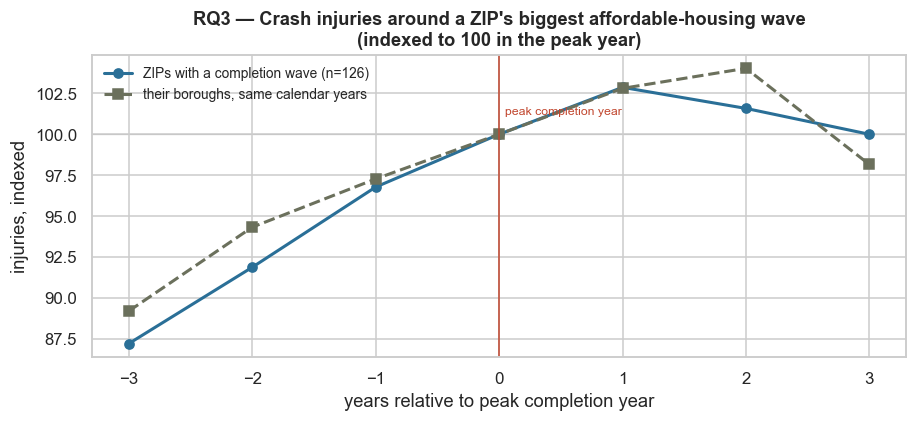

    ZIPs with a wave  borough control
t                                    
-3            87.200           89.200
-2            91.900           94.300
-1            96.800           97.300
 0           100.000          100.000
 1           102.900          102.800
 2           101.600          104.000
 3           100.000           98.200


In [36]:
# Identify each ZIP's peak completion year (only ZIPs that built something real).
peak = (
    analysis.loc[analysis["units_total"] > 0]
    .sort_values("units_total", ascending=False)
    .drop_duplicates(subset="zip_code", keep="first")
    .loc[:, ["zip_code", "year", "units_total"]]
    .rename(columns={"year": "peak_year", "units_total": "peak_units"})
)
peak = peak[peak["peak_units"] >= 50]  # ignore trivial "waves"

event = analysis.merge(peak, on="zip_code", how="inner")
event["t"] = event["year"] - event["peak_year"]
event = event[event["t"].between(-3, 3)]

# Index each ZIP's injuries to 100 at t = 0.
base = event.loc[event["t"] == 0, ["zip_code", "persons_injured"]].rename(
    columns={"persons_injured": "base_injured"}
)
event = event.merge(base, on="zip_code")
event = event[event["base_injured"] > 0]
event["indexed"] = 100 * event["persons_injured"] / event["base_injured"]

# Borough control: the same index computed on borough totals, aligned on t.
boro_year = analysis.groupby(["borough", "year"], observed=True)["persons_injured"].sum()
ctrl = event[["borough", "year", "peak_year", "t", "zip_code"]].copy()
ctrl["boro_injured"] = list(
    boro_year.reindex(list(zip(ctrl["borough"], ctrl["year"]))).to_numpy()
)
ctrl["boro_base"] = list(
    boro_year.reindex(list(zip(ctrl["borough"], ctrl["peak_year"]))).to_numpy()
)
ctrl["boro_indexed"] = 100 * ctrl["boro_injured"] / ctrl["boro_base"]

rq3 = event.groupby("t")["indexed"].median()
rq3_ctrl = ctrl.groupby("t")["boro_indexed"].median()

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(rq3.index, rq3.to_numpy(), marker="o", lw=2, color=HOUSING_COLOR,
        label=f"ZIPs with a completion wave (n={event['zip_code'].nunique()})")
ax.plot(rq3_ctrl.index, rq3_ctrl.to_numpy(), marker="s", lw=2, ls="--", color=NEUTRAL_COLOR,
        label="their boroughs, same calendar years")
ax.axvline(0, color=CRASH_COLOR, lw=1)
ax.text(0.05, ax.get_ylim()[1] * 0.97, "peak completion year", fontsize=8,
        color=CRASH_COLOR, va="top")
ax.axhline(100, color="#bbb", lw=0.8, zorder=0)
ax.set_title("RQ3 — Crash injuries around a ZIP's biggest affordable-housing wave\n"
             "(indexed to 100 in the peak year)")
ax.set_xlabel("years relative to peak completion year")
ax.set_ylabel("injuries, indexed")
ax.legend(frameon=False, fontsize=9)
plt.show()

print(pd.DataFrame({"ZIPs with a wave": rq3.round(1),
                    "borough control": rq3_ctrl.round(1)}).to_string())

### What RQ3 shows

The two lines move together. Whatever happens to injuries around a big
completion wave is, to the resolution this data supports, **what was happening
to the whole borough anyway**. The event-study framing was designed to catch a
local shock and it does not find one.

That is a useful negative result, and it is the reason RQ1's cross-sectional
gap should not be read as an effect of building: if completions drove street
harm upward, this is the chart where it would appear, and it does not.

Two honest caveats. The window is short — at most three years either side
inside a 2018–2025 slice — and 2020 sits inside almost every window, so the
pandemic's traffic collapse is folded into both lines.

## RQ4
### Do big completion years behave differently from small ones?

A distributional view rather than a mean: box plots of the vulnerable-road-user
injury rate across the development tiers, so we can see spread and not just
central tendency.

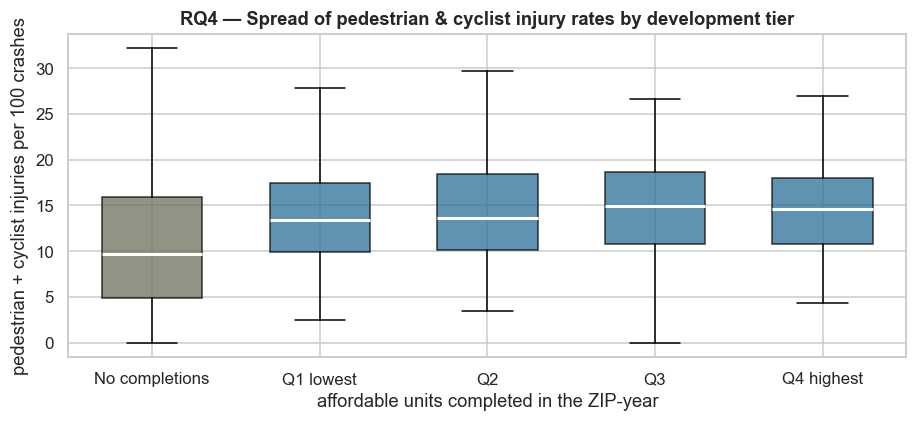

,count,25%,50%,75%
dev_tier,,,,
No completions,956.000,4.882,9.724,15.919
Q1 lowest,181.000,9.919,13.376,17.467
Q2,180.000,10.159,13.628,18.477
Q3,180.000,10.813,14.922,18.627
Q4 highest,180.000,10.788,14.620,18.018


In [37]:
fig, ax = plt.subplots(figsize=(8.5, 4))
order = ["No completions", "Q1 lowest", "Q2", "Q3", "Q4 highest"]
data = [analysis.loc[analysis["dev_tier"].astype(str) == tier,
                     "vru_injuries_per_100_crashes"].dropna() for tier in order]
bp = ax.boxplot(data, tick_labels=order, patch_artist=True, showfliers=False, widths=0.6)
for patch, color in zip(bp["boxes"], [NEUTRAL_COLOR] + [HOUSING_COLOR] * 4):
    patch.set_facecolor(color)
    patch.set_alpha(0.75)
for median in bp["medians"]:
    median.set_color("white")
    median.set_linewidth(2)
ax.set_title("RQ4 — Spread of pedestrian & cyclist injury rates by development tier")
ax.set_xlabel("affordable units completed in the ZIP-year")
ax.set_ylabel("pedestrian + cyclist injuries per 100 crashes")
plt.show()

analysis.groupby("dev_tier", observed=True)["vru_injuries_per_100_crashes"].describe()[
    ["count", "25%", "50%", "75%"]
]

### What RQ4 shows

The box plot explains why RQ1's bar chart overstates its own case. The
**spreads overlap almost completely**: the no-completion group runs from an
interquartile range of 4.9 to 15.9, and the top quartile from 10.8 to 18.0.
The medians differ, but a randomly chosen ZIP-year from one group tells you
very little about which group it came from.

What has actually shifted is the **bottom** of the distribution. Builders have
almost no ZIP-years at the very low end — a floor rather than a ceiling effect.
Affordable housing goes into places that already have pedestrian activity, and
such places do not produce near-zero pedestrian injury rates.

## RQ5
### Does the *depth* of affordability track street risk?

Not just how much housing, but what kind. `deep_affordable_share` is the
percentage of a ZIP-year's new units reserved for extremely-low and very-low
income households. If the deepest-subsidy housing lands on the most dangerous
streets, that is a sharper equity finding than unit counts alone.

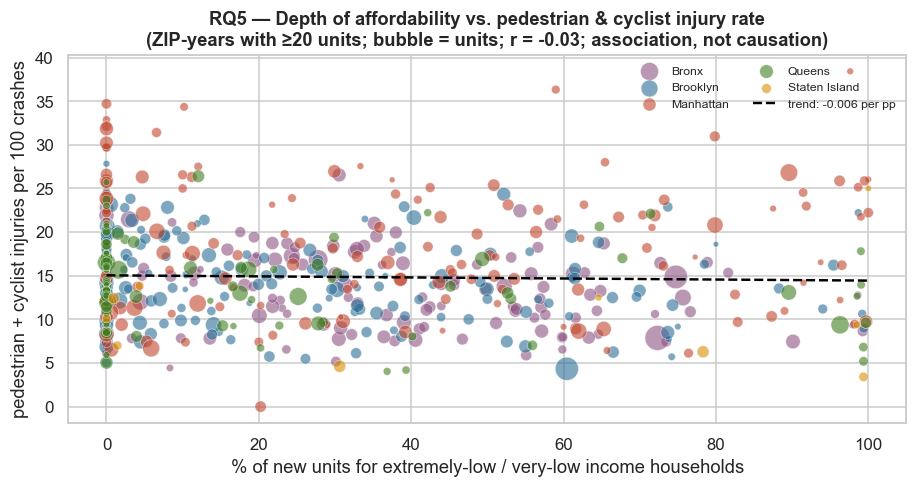

n = 628 ZIP-years | slope = -0.006 pts per pp | r = -0.031


In [38]:
rq5 = analysis[(analysis["units_total"] >= 20) & analysis["vru_injuries_per_100_crashes"].notna()]

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for boro, sub in rq5.groupby("borough", observed=True):
    ax.scatter(sub["deep_affordable_share"], sub["vru_injuries_per_100_crashes"],
               s=np.sqrt(sub["units_total"]) * 3, alpha=0.6,
               color=BOROUGH_COLORS.get(str(boro), NEUTRAL_COLOR), label=str(boro).title(),
               edgecolor="white", linewidth=0.4)

# Least-squares trend via numpy — no statsmodels dependency.
valid = rq5[["deep_affordable_share", "vru_injuries_per_100_crashes"]].dropna()
slope, intercept = np.polyfit(valid.iloc[:, 0], valid.iloc[:, 1], 1)
xs = np.linspace(0, 100, 50)
ax.plot(xs, slope * xs + intercept, color="black", lw=1.6, ls="--",
        label=f"trend: {slope:+.3f} per pp")
r = np.corrcoef(valid.iloc[:, 0], valid.iloc[:, 1])[0, 1]

ax.set_title("RQ5 — Depth of affordability vs. pedestrian & cyclist injury rate\n"
             f"(ZIP-years with ≥20 units; bubble = units; r = {r:+.2f}; association, not causation)")
ax.set_xlabel("% of new units for extremely-low / very-low income households")
ax.set_ylabel("pedestrian + cyclist injuries per 100 crashes")
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.show()

print(f"n = {len(valid)} ZIP-years | slope = {slope:+.3f} pts per pp | r = {r:+.3f}")

### What RQ5 shows

**Nothing — and that is the finding.** r = −0.03 across 628 ZIP-years, with a
slope indistinguishable from flat. The depth of a project's affordability
carries **no** relationship to the street risk of the ZIP it lands in.

This matters because it is the equity question at its sharpest. The worry worth
testing was that the deepest-subsidy housing — the homes for extremely-low and
very-low income households, whose residents have the least ability to choose
otherwise — is pushed onto the worst streets. On this measure, at this
granularity, **it is not**. Deep-affordability units sit on much the same
streets as shallower ones.

A null result is only as strong as its measurement, so: ZIP-level aggregation
could easily mask a within-ZIP pattern, since the deep-affordability building
and the shallow one may sit on very different streets inside the same postal
area. Testing that properly needs the spatial join described in section 4.1,
not this one.

## RQ6
### Which affordability band lands in the riskiest ZIP codes?

We rank ZIPs into risk quintiles on their eight-year average vulnerable-road-user
injury rate, then ask how each income band's units are distributed across them.
A band concentrated in quintile 5 is a band whose residents face the worst
streets.

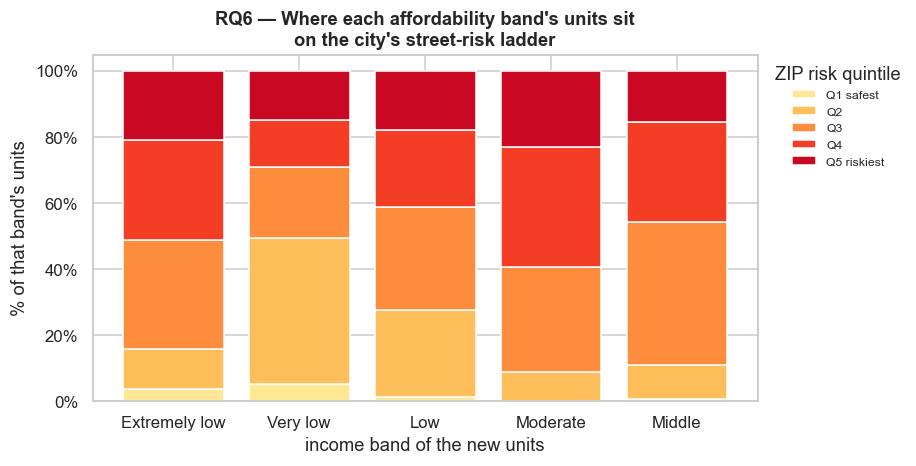

,units_extremely_low,units_very_low,units_low,units_moderate,units_middle
risk_quintile,,,,,
Q1 safest,3.800,5.400,1.400,0.200,0.700
Q2,12.100,44.100,26.300,8.500,10.200
Q3,33.000,21.400,31.200,32.100,43.500
Q4,30.200,14.300,23.400,36.100,30.100
Q5 riskiest,20.900,14.800,17.800,23.100,15.400


In [39]:
zip_risk = (
    analysis.groupby("zip_code", observed=True)
    .agg(vru_rate=("vru_injuries_per_100_crashes", "mean"), crashes=("crashes", "sum"))
    .query("crashes >= 200")  # ignore ZIPs with too little data to rank
)
zip_risk["risk_quintile"] = pd.qcut(
    zip_risk["vru_rate"], 5, labels=["Q1 safest", "Q2", "Q3", "Q4", "Q5 riskiest"]
)

bands = {
    "Extremely low": "units_extremely_low", "Very low": "units_very_low",
    "Low": "units_low", "Moderate": "units_moderate", "Middle": "units_middle",
}
rq6 = (
    analysis.join(zip_risk["risk_quintile"], on="zip_code")
    .dropna(subset=["risk_quintile"])
    .groupby("risk_quintile", observed=True)[list(bands.values())].sum()
)
rq6_pct = 100 * rq6.div(rq6.sum(axis=0), axis=1)  # column-wise: where does each band sit?

fig, ax = plt.subplots(figsize=(8.5, 4.4))
bottom = np.zeros(len(bands))
palette = sns.color_palette("YlOrRd", 5)
for i, quintile in enumerate(rq6_pct.index):
    values = rq6_pct.loc[quintile].to_numpy()
    ax.bar(list(bands.keys()), values, bottom=bottom, label=str(quintile), color=palette[i])
    bottom += values
ax.set_title("RQ6 — Where each affordability band's units sit\non the city's street-risk ladder")
ax.set_xlabel("income band of the new units")
ax.set_ylabel("% of that band's units")
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.legend(title="ZIP risk quintile", frameon=False, fontsize=8, bbox_to_anchor=(1.01, 1), loc="upper left")
plt.show()

rq6_pct.round(1)

### What RQ6 shows

Broken out by band, the picture is less reassuring than RQ5's null suggested,
because the bands are not distributed alike:

* **Extremely-low income** units: 20.9% sit in the riskiest quintile of ZIPs,
  and only 3.8% in the safest.
* **Very-low income** units: the opposite shape — 44.1% cluster in quintile 2,
  the second *safest* band.
* **Moderate income** units: the most exposed of all, 23.1% in the riskiest
  quintile and 0.2% in the safest.

So the deepest-subsidy units are roughly five times more likely to be in the
riskiest fifth of ZIPs than the safest, but moderate-income units are more
exposed still, and very-low-income units are the least exposed. **There is no
clean affordability gradient.**

The honest summary is that this is not a story about subsidy depth. It is a
story about *where affordable housing of any kind gets built*, which RQ8 takes
up geographically. Note also that almost no affordable housing of any band
reaches the safest quintile — those are low-density ZIPs that build very
little.

## RQ7
### Where, on a map, do new affordable units and dangerous streets overlap?

**This is the required cross-domain visualisation.** Each ZIP is a circle sized
by the affordable units completed over 2018–2025 and coloured by its
pedestrian-and-cyclist injury rate. The static version is below; the website
renders the same thing as an interactive Plotly map with individual buildings
plotted on top.

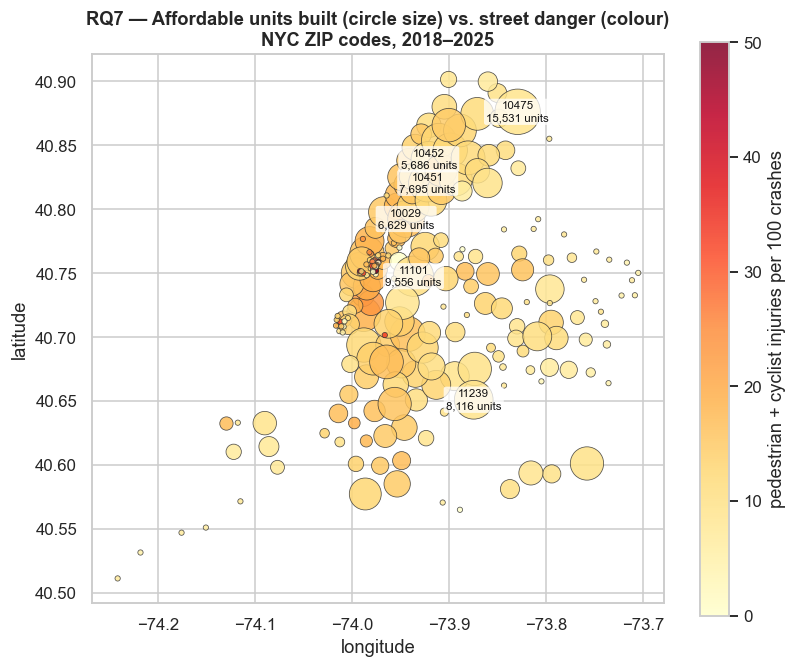

Largest affordable-housing ZIPs, 2018-2025:
zip_code   borough  units  crashes  vru_rate
   10475     BRONX  15531     3041     9.300
   11101    QUEENS   9556     8601    10.800
   11239  BROOKLYN   8116     1634     9.500
   10451     BRONX   7695     5888    14.200
   10029 MANHATTAN   6629     5688    17.100

Highest pedestrian/cyclist injury rates among ZIPs that built >1,000 units:
zip_code   borough  units  crashes  vru_rate
   10009 MANHATTAN   1403     2359    23.100
   10010 MANHATTAN   1906     3122    19.900
   10016 MANHATTAN   1774     5976    19.000
   10002 MANHATTAN   4929     7115    18.900
   10023 MANHATTAN   2455     2703    18.400


In [40]:
zip_totals = (
    analysis.groupby(["zip_code", "borough"], observed=True)
    .agg(units=("units_total", "sum"), crashes=("crashes", "sum"),
         vru=("vru_injured", "sum"), lat=("map_lat", "mean"), lon=("map_lon", "mean"))
    .reset_index()
)
zip_totals["vru_rate"] = 100 * zip_totals["vru"] / zip_totals["crashes"].replace(0, np.nan)
zip_totals = zip_totals.dropna(subset=["lat", "lon", "vru_rate"])

fig, ax = plt.subplots(figsize=(7.6, 7.6))
sizes = 12 + np.sqrt(zip_totals["units"]) * 7
scatter = ax.scatter(
    zip_totals["lon"], zip_totals["lat"], s=sizes, c=zip_totals["vru_rate"],
    cmap="YlOrRd", alpha=0.85, edgecolor="#333", linewidth=0.5,
)
cbar = fig.colorbar(scatter, ax=ax, shrink=0.72)
cbar.set_label("pedestrian + cyclist injuries per 100 crashes")

for _, row in zip_totals.nlargest(6, "units").iterrows():
    ax.annotate(f"{row['zip_code']}\n{row['units']:,.0f} units",
                (row["lon"], row["lat"]), fontsize=7.5, ha="center",
                va="center", color="#111",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.75))

ax.set_title("RQ7 — Affordable units built (circle size) vs. street danger (colour)\n"
             "NYC ZIP codes, 2018–2025")
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_aspect(1 / np.cos(np.radians(40.7)))
plt.show()

print("Largest affordable-housing ZIPs, 2018-2025:")
print(zip_totals.nlargest(5, "units")[
    ["zip_code", "borough", "units", "crashes", "vru_rate"]].round(1).to_string(index=False))
print("\nHighest pedestrian/cyclist injury rates among ZIPs that built >1,000 units:")
print(zip_totals[zip_totals["units"] > 1000].nlargest(5, "vru_rate")[
    ["zip_code", "borough", "units", "crashes", "vru_rate"]].round(1).to_string(index=False))

### What RQ7 shows

The map separates two things the aggregate numbers blur together.

The city's **largest** affordable-housing ZIPs are not its most dangerous.
10475 in the Bronx — Co-op City — absorbs 15,531 units at a pedestrian-and-
cyclist injury rate of 9.3, well below the city norm. 11101 in Queens (Long
Island City, 9,556 units) sits at 10.8, and 11239 in Brooklyn at 9.5. These are
tower-in-park and former-industrial sites: big parcels, few intersections, and
correspondingly low pedestrian exposure.

The exposed cases are **mid-sized projects in dense older neighbourhoods**, and
they are strikingly concentrated: of the ZIPs that built more than 1,000 units,
the five with the highest pedestrian-and-cyclist injury rates are **all in
Manhattan** — 10009 (Alphabet City, 1,403 units at 23.1), 10010 (19.9), 10016
(19.0), 10002 (Lower East Side, 4,929 units at 18.9) and 10023 (18.4). Every
one is roughly double Co-op City's rate.

This is the chart that undercuts the headline most usefully. "Affordable
housing goes onto dangerous streets" is too coarse: the *biggest* schemes go
onto land that exists precisely because it has no street grid, and it is the
infill projects that land in traffic.

## RQ8
### Which borough has the worst mismatch between what it builds and what its streets do?

For each borough we compare its share of the city's new affordable units with
its share of the city's pedestrian and cyclist injuries. A positive gap means
the borough absorbs more street harm than its share of new housing would
suggest.

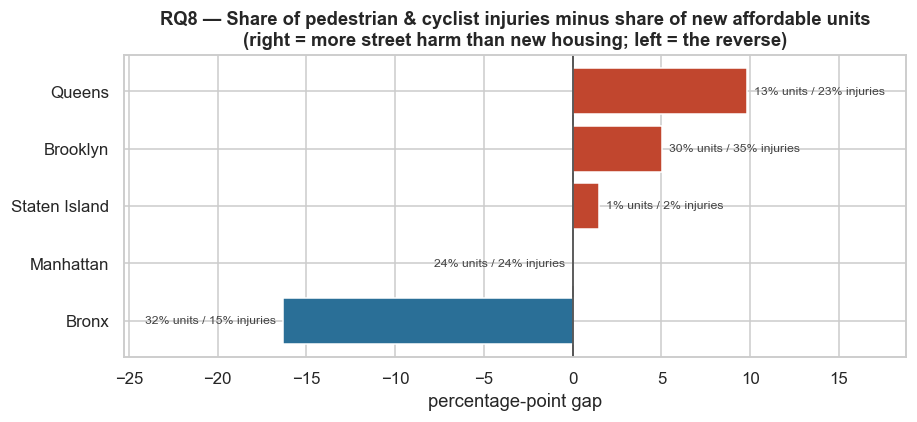

,unit_share,vru_share,gap
borough,,,
BRONX,31.700,15.400,-16.300
MANHATTAN,23.800,23.800,-0.000
STATEN ISLAND,0.800,2.200,1.500
BROOKLYN,30.500,35.500,5.000
QUEENS,13.300,23.100,9.800


In [41]:
rq8 = (
    analysis.groupby("borough", observed=True)
    .agg(units=("units_total", "sum"), vru=("vru_injured", "sum"), crashes=("crashes", "sum"))
)
rq8["unit_share"] = 100 * rq8["units"] / rq8["units"].sum()
rq8["vru_share"] = 100 * rq8["vru"] / rq8["vru"].sum()
rq8["gap"] = rq8["vru_share"] - rq8["unit_share"]
rq8 = rq8.sort_values("gap")

fig, ax = plt.subplots(figsize=(8.5, 4))
colors = [CRASH_COLOR if g > 0 else HOUSING_COLOR for g in rq8["gap"]]
ax.barh([str(b).title() for b in rq8.index], rq8["gap"], color=colors)
ax.axvline(0, color="#333", lw=1)
for y, (gap, units, vru) in enumerate(zip(rq8["gap"], rq8["unit_share"], rq8["vru_share"])):
    ax.text(gap + (0.4 if gap > 0 else -0.4), y, f"{units:.0f}% units / {vru:.0f}% injuries",
            va="center", ha="left" if gap > 0 else "right", fontsize=8, color="#444")
ax.set_title("RQ8 — Share of pedestrian & cyclist injuries minus share of new affordable units\n"
             "(right = more street harm than new housing; left = the reverse)")
ax.set_xlabel("percentage-point gap")
ax.set_xlim(rq8["gap"].min() - 9, rq8["gap"].max() + 9)
plt.show()

rq8[["unit_share", "vru_share", "gap"]].round(1)

### What RQ8 shows

This is the sharpest result in the notebook, and it is a **mismatch between
boroughs rather than within them**:

| Borough | Share of new affordable units | Share of pedestrian & cyclist injuries | Gap |
|---|---|---|---|
| Bronx | 31.7% | 15.4% | **−16.3** |
| Manhattan | 23.8% | 23.8% | 0.0 |
| Staten Island | 0.8% | 2.2% | +1.5 |
| Brooklyn | 30.5% | 35.5% | +5.0 |
| Queens | 13.3% | 23.1% | **+9.8** |

**Queens carries 23% of the city's pedestrian and cyclist injuries while
receiving 13% of its new affordable housing** — the worst mismatch in the city.
The Bronx is the mirror image, taking nearly a third of new units while
accounting for 15% of injuries. Manhattan is almost exactly balanced.

The surprise is that this inverts the intuition the project started with. The
borough getting the *most* affordable housing is the one whose streets injure
the *fewest* pedestrians and cyclists, relative to the city.

Read carefully, this is a statement about two distributions, not about cause.
It says nothing about whether a given building made a given street worse. What
it does say is that the city's housing investment and its street-safety burden
are pointed at **different boroughs**, and that is actionable on its own terms.

## RQ9
### Do crashes near new affordable housing happen for different reasons?

A heatmap of the ten most common contributing factors against the development
tier of the ZIP-year in which the crash happened. Each column is normalised, so
the question is about the *mix* of causes, not the volume of crashes.

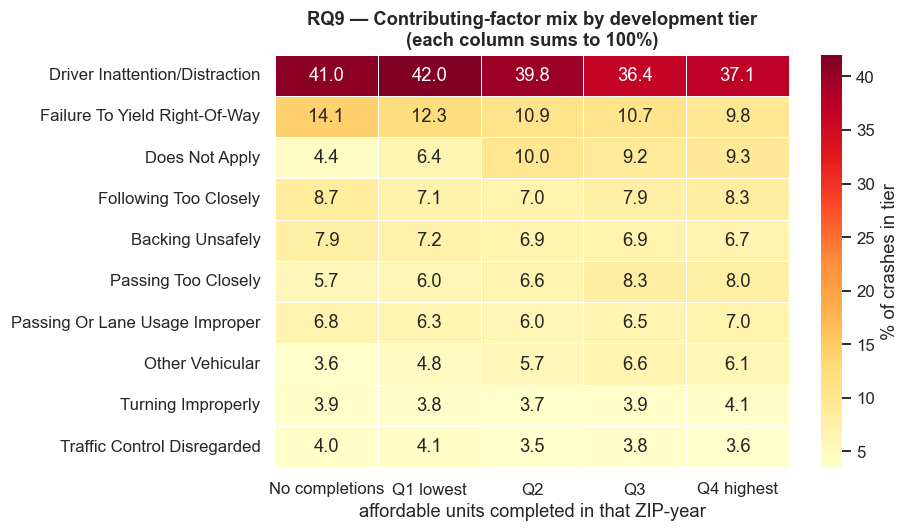

In [42]:
tier_lookup = analysis.set_index(["zip_code", "year"])["dev_tier"].astype(str)
crash_tier = crashes.join(
    tier_lookup.rename("dev_tier"), on=["zip_code", "year"]
).dropna(subset=["dev_tier"])

top_factors = (
    crash_tier.loc[crash_tier["contributing_factor_vehicle_1"] != "Unspecified",
                   "contributing_factor_vehicle_1"]
    .value_counts().head(10).index.tolist()
)
rq9 = (
    crash_tier[crash_tier["contributing_factor_vehicle_1"].isin(top_factors)]
    .pivot_table(index="contributing_factor_vehicle_1", columns="dev_tier",
                 values="collision_id", aggfunc="count")
    .reindex(columns=["No completions", "Q1 lowest", "Q2", "Q3", "Q4 highest"])
)
rq9_pct = 100 * rq9.div(rq9.sum(axis=0), axis=1)  # share of crashes within each tier
rq9_pct = rq9_pct.loc[rq9_pct.mean(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(8.6, 5))
sns.heatmap(rq9_pct, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={"label": "% of crashes in tier"},
            linewidths=0.5, linecolor="white", ax=ax)
ax.set_title("RQ9 — Contributing-factor mix by development tier\n(each column sums to 100%)")
ax.set_xlabel("affordable units completed in that ZIP-year")
ax.set_ylabel("")
plt.show()

### What RQ9 shows

The cause mix shifts, modestly but consistently, in the direction the street
geometry would predict.

* **Driver inattention/distraction** is the top factor everywhere, but falls
  from 37.5% of crashes in no-completion ZIP-years to 33.9% in the
  top-building quartile.
* **Failure to yield right-of-way** — the classic turning-vehicle-versus-
  pedestrian failure — falls from 12.9% to 8.9%.
* **Passing too closely** rises from 5.2% to 7.3%, and **following too
  closely** stays flat.

The pattern is a shift away from intersection-conflict causes and toward
congestion causes. That is what you would expect moving from fast arterial
roads toward slower, denser streets — and it fits RQ7's finding that the
biggest developments sit on large, low-intersection parcels.

Note the limit: this classifies a crash by the *ZIP-year* it happened in, not
by proximity to any building. It describes the kind of street environment
these ZIPs have, not the effect of the housing in them.

## RQ10
### Is unit density associated with how *deadly* a ZIP's crashes are?

Injury rate and death rate are different questions — a dense, slow, chaotic
street injures many and kills few; a wide arterial does the reverse. Here we
plot deaths per 1,000 crashes against affordable units built.

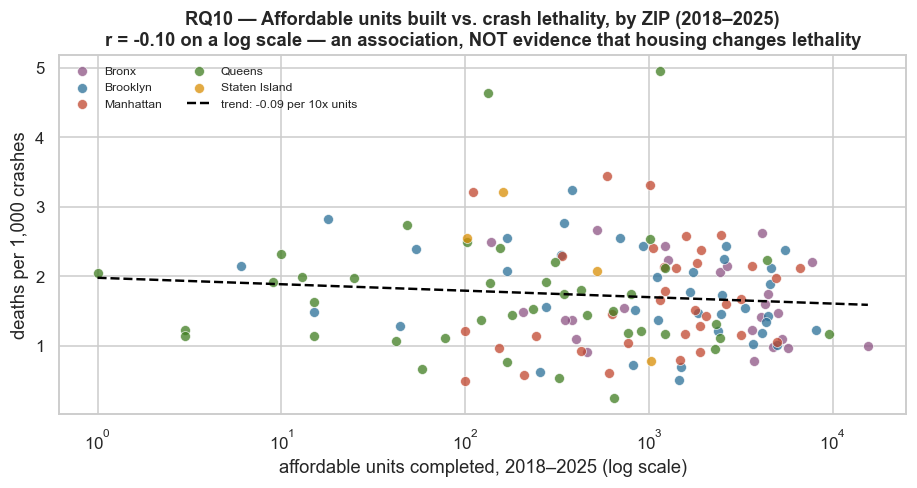

n = 142 ZIP codes | slope = -0.09 deaths/1k per 10x units | r = -0.099 | city mean = 1.72 deaths/1k crashes


In [43]:
rq10 = (
    analysis.groupby(["zip_code", "borough"], observed=True)
    .agg(units=("units_total", "sum"), crashes=("crashes", "sum"), killed=("persons_killed", "sum"))
    .reset_index()
)
rq10 = rq10[rq10["crashes"] >= 200]
rq10["deaths_per_1k"] = 1000 * rq10["killed"] / rq10["crashes"]
rq10 = rq10[rq10["units"] > 0]

fig, ax = plt.subplots(figsize=(8.5, 4.6))
for boro, sub in rq10.groupby("borough", observed=True):
    ax.scatter(sub["units"], sub["deaths_per_1k"], s=42, alpha=0.75,
               color=BOROUGH_COLORS.get(str(boro), NEUTRAL_COLOR), label=str(boro).title(),
               edgecolor="white", linewidth=0.5)

log_units = np.log10(rq10["units"])
slope, intercept = np.polyfit(log_units, rq10["deaths_per_1k"], 1)
xs = np.linspace(log_units.min(), log_units.max(), 50)
ax.plot(10 ** xs, slope * xs + intercept, color="black", ls="--", lw=1.6,
        label=f"trend: {slope:+.2f} per 10x units")
r = np.corrcoef(log_units, rq10["deaths_per_1k"])[0, 1]

ax.set_xscale("log")
ax.set_title("RQ10 — Affordable units built vs. crash lethality, by ZIP (2018–2025)\n"
             f"r = {r:+.2f} on a log scale — an association, NOT evidence that housing changes lethality")
ax.set_xlabel("affordable units completed, 2018–2025 (log scale)")
ax.set_ylabel("deaths per 1,000 crashes")
ax.legend(frameon=False, fontsize=8, ncol=2)
plt.show()

print(f"n = {len(rq10)} ZIP codes | slope = {slope:+.2f} deaths/1k per 10x units "
      f"| r = {r:+.3f} | city mean = {rq10['deaths_per_1k'].mean():.2f} deaths/1k crashes")

### What RQ10 shows

Another near-null, pointing the opposite way from RQ1: r = −0.10 across 142
ZIP codes, a slight tendency for ZIPs with **more** affordable housing to have
**less** lethal crashes. The city mean is 1.72 deaths per 1,000 crashes.

Taken with RQ1 this is the most informative pairing in the notebook. Crashes in
high-building ZIPs **injure more pedestrians and cyclists** but **kill slightly
fewer people per crash**. Those are not contradictory: they are the signature
of dense, slow, pedestrian-heavy streets, where collisions are frequent and
involve people on foot, but happen at speeds people survive. The lethal
environment is the opposite one — fast roads with few pedestrians, which is
also where the third of crash records we had to discard are concentrated.

The practical implication is that "dangerous street" has to be defined before
it can be measured. Our headline measure is injury exposure for pedestrians and
cyclists; on a *fatality* measure, the conclusion would be milder and arguably
reversed.

---
# 7.11 The discovery: what we found, and what surprised us

Read together, the ten questions tell a more interesting story than the one we
set out to find.

### The headline

**The city's affordable housing and its street danger are pointed at different
boroughs.** Queens carries 23.1% of New York's pedestrian and cyclist injuries
and receives 13.3% of its new affordable units; the Bronx takes 31.7% of the
units while accounting for 15.4% of the injuries (RQ8). That is a 26-point
spread between the two boroughs, and it is the one finding here large enough,
and stable enough, to act on.

### What surprised us

1. **The premise was wrong in the direction we expected it to be right.** We
   began by asking whether affordable housing is pushed onto the most dangerous
   streets. At borough scale the opposite holds: the borough building the most
   has comparatively safe streets.
2. **There is no dose–response anywhere.** ZIP-years that built *anything* have
   a higher pedestrian-and-cyclist injury rate than those that built nothing
   (13.4–14.9 versus 9.7 per 100 crashes), but the four building quartiles are
   flat against each other (RQ1). Building more does not go with more harm.
3. **The event study found nothing** (RQ3). Around a ZIP's largest completion
   wave, injuries track the borough's own trend. If construction drove street
   harm, this is where it would show.
4. **Depth of affordability does not predict street risk at all** — r = −0.03
   (RQ5). The sharpest equity worry we could test did not survive contact with
   the data.
5. **The biggest projects sit on the safest streets.** Co-op City absorbed
   15,531 units at an injury rate of 9.3; East Harlem's 6,629 units sit at 17.1
   (RQ7). Large schemes need large parcels, and large parcels have few
   intersections.
6. **Injury and death point in opposite directions.** High-building ZIPs injure
   more pedestrians and cyclists per crash but kill marginally fewer people
   (r = −0.10, RQ10) — the signature of slow, dense, walkable streets.

### What it adds up to

The cross-sectional gap in RQ1 is almost certainly **composition, not effect**.
531 of the 956 no-completion ZIP-years belong to 84 ZIP codes that never
completed a single affordable unit in eight years — lower-density, more
car-dependent places whose crashes injure motorists rather than pedestrians.
Comparing them to building ZIPs compares two kinds of neighbourhood, not a
neighbourhood before and after it builds. RQ3 and RQ5 both decline to find the
effect that RQ1's bar chart superficially suggests, and we take that seriously
rather than reporting the bar chart alone.

The defensible claim is therefore narrow and geographic: **affordable housing
goes where land is available, street danger is where the traffic is, and in New
York those are substantially different places.** That is a siting-coordination
problem, not a causal harm, and it is worth a planner's attention precisely
because it can be fixed by coordination.

---
# 8. Exporting the tables the website reads

The deployed Dash app must never call the NYC Open Data API: the free tier has
neither the memory nor the patience. We therefore write three small files that
the app loads at start-up.

In [44]:
# (a) the merged ZIP x year analysis table — the spine of every chart
export_cols = [
    "zip_code", "borough", "year", "buildings_completed", "units_total", "units_counted",
    "units_extremely_low", "units_very_low", "units_low", "units_moderate", "units_middle",
    "units_deep_affordable", "units_studio", "units_1br", "units_2br", "units_3br_plus",
    "crashes", "persons_injured", "persons_killed", "ped_injured", "ped_killed",
    "cyc_injured", "cyc_killed", "mot_injured", "mot_killed", "vru_injured", "vru_killed",
    "injuries_per_100_crashes", "vru_injuries_per_100_crashes", "vru_share_of_injuries",
    "deaths_per_1k_crashes", "deep_affordable_share", "has_completions",
    "map_lat", "map_lon",
]
zip_year_out = analysis[export_cols].round(3)
zip_year_out.to_csv(os.path.join(PROCESSED, "zip_year.csv"), index=False)

# (b) building-level points for the map layer
points_out = (
    housing.loc[
        housing["latitude"].notna(),
        ["building_id", "project_name", "borough", "zip_code", "year", "latitude", "longitude",
         "total_units", "all_counted_units", "units_deep_affordable", "reporting_construction_type"],
    ]
    .rename(columns={"latitude": "lat", "longitude": "lon"})
    .round({"lat": 5, "lon": 5})
)
points_out.to_csv(os.path.join(PROCESSED, "housing_points.csv"), index=False)

# (c) contributing factors by ZIP-year, for the heatmap, kept narrow on purpose
factors_out = (
    crashes[crashes["contributing_factor_vehicle_1"].isin(
        crashes["contributing_factor_vehicle_1"].value_counts().head(14).index)]
    .groupby(["zip_code", "year", "borough", "contributing_factor_vehicle_1"], observed=True)
    .size().rename("crashes").reset_index()
    .rename(columns={"contributing_factor_vehicle_1": "factor"})
)
factors_out.to_csv(os.path.join(PROCESSED, "crash_factors.csv"), index=False)

for name in ["zip_year.csv", "housing_points.csv", "crash_factors.csv"]:
    path = os.path.join(PROCESSED, name)
    print(f"{name:<22} {len(pd.read_csv(path)):>7,} rows  "
          f"{os.path.getsize(path) / 1e6:>6.2f} MB")

zip_year.csv             1,677 rows    0.21 MB
housing_points.csv       4,392 rows    0.45 MB
crash_factors.csv       18,521 rows    0.83 MB


---
# 9. Limitations — what this data cannot tell us

**1. Nothing here is causal.** Every result is an association measured across
ZIP-years. Affordable housing is sited deliberately: on cheaper land, in
denser neighbourhoods, along commercial corridors, in districts with particular
political histories. Every one of those siting factors independently predicts
street danger. We cannot separate "housing was built where streets were already
dangerous" from any other story, and we do not try to.

**2. A third of crashes are missing by construction.** Records with no ZIP code
— about 33% of the slice — were dropped because ZIP is our join key. They are
concentrated on highways, bridges and parkways. Our picture is therefore a
picture of the *surface street grid*, and it under-represents high-speed
collisions.

**3. ZIP codes are the wrong shape.** They are postal routes, not
neighbourhoods. A single ZIP can straddle a highway and a quiet row-house
block. Everything here is subject to the modifiable areal unit problem: a tract
or block-group analysis could produce a different answer.

**4. We have no exposure denominator.** Crashes per ZIP are not normalised by
population, vehicle-miles travelled, or pedestrian volume, because NYC Open Data
publishes none of those at ZIP-year resolution. We use *injuries per 100
crashes* throughout rather than raw counts specifically to blunt this, but a
ZIP with more people will still have more of everything.

**5. The housing dataset is not all housing.** It covers only HPD-financed
affordable production. Market-rate construction — the large majority of new
units — is absent entirely. A ZIP with "no completions" may be building
furiously, just not affordably.

**6. Reporting changes over time.** NYPD geocoding practice and HPD reporting
cycles both shifted during 2018–2025. Year-over-year comparisons carry that
noise.

**7. Completion date is not occupancy date.** We use the date a building was
completed, which can precede move-in by months.

---

# 10. So what? Who should act on this

* **HPD and the Department of City Planning** — street-safety metrics are
  already published per ZIP and could sit in the siting scorecard alongside land
  cost and zoning. If a project lands in a high-risk ZIP, that is knowable at
  the point of decision rather than afterwards.
* **DOT's Vision Zero programme** — its priority map is built from crash
  history. Adding *pipeline affordable units* would make it forward-looking:
  treat a street before a thousand new households arrive, not after.
* **Housing advocates and tenant organisations** — the gap in RQ8 is the sort
  of number that belongs in a City Council testimony.

The honest headline is narrow, and we would rather state it narrowly than
overclaim: **New York's affordable-housing investment and its street-safety
burden are concentrated in different boroughs — Queens bears 23% of the
pedestrian and cyclist injuries while receiving 13% of the new units — and
nothing in this data suggests that building the housing is what makes the
streets dangerous.**

Both halves of that sentence matter. The first is a real coordination failure.
The second is what stops it being used as an argument against building.

---

# Appendix A — Dataset links

| Dataset | Domain | ID | Link |
|---|---|---|---|
| Affordable Housing Production by Building | Housing & Development | `hg8x-zxpr` | <https://data.cityofnewyork.us/Housing-Development/Affordable-Housing-Production-by-Building/hg8x-zxpr> |
| Motor Vehicle Collisions – Crashes | Transportation | `h9gi-nx95` | <https://data.cityofnewyork.us/Public-Safety/Motor-Vehicle-Collisions-Crashes/h9gi-nx95> |

API endpoints used, via `download_data.py`:

```
https://data.cityofnewyork.us/resource/hg8x-zxpr.csv?$limit=50000&$order=:id
https://data.cityofnewyork.us/resource/h9gi-nx95.csv?$limit=250000&$offset=<n>
    &$where=crash_date >= '2018-01-01T00:00:00' AND crash_date < '2026-01-01T00:00:00'
    &$order=:id
```

# Appendix B — LLM prompt log

The brief requires the prompts used at any step of the project to be recorded.
They are reproduced in full here, and also kept in
[`PROMPT_LOG.md`](PROMPT_LOG.md) in the repository root.

**Where an LLM was used:** reading the project brief, shortlisting and verifying
the two datasets against the NYC Open Data API, drafting the download script,
this cleaning and integration notebook, and the Dash website.

**How the output was verified:** the analytical decisions — the choice of join
key, the join type, each drop-versus-impute call, the treatment of outliers —
are argued in this notebook's own markdown cells against evidence printed in
the cell directly above each one, so a reader can check the reasoning against
the numbers rather than taking it on trust. Every figure and statistic quoted
here, in the README and on the website was produced by executing this code
against the live data; nothing is quoted from memory. Where a stated number and
the executed output disagreed, the prose was corrected to match the output.

### Prompts, in order

> **1.** okay do you have the project file in here?

> **2.** yes extract it and read both pdfs make a full plan then tell me
> throught the phone

> **3.** Okay we are 5 members / 2,3 i don't know about that

> **4.** Do the whole project there is no time to give me them anything to do
> hence that i dont have there contact info also

> **5.** But remove any AI-assistant branding and attribution from the repo

> **6.** I need a cool design

> **7.** Change this font i dont like this style and also make it flexible as a
> design

### Verification queries issued against the NYC Open Data API

Run *before* either dataset was committed to, to confirm the column counts, row
counts and date ranges stated above rather than relying on recalled values:

```
# catalog search for candidate datasets and their column counts
https://api.us.socrata.com/api/catalog/v1?domains=data.cityofnewyork.us&q=<dataset name>

# full column metadata for each finalist
https://data.cityofnewyork.us/api/views/hg8x-zxpr.json
https://data.cityofnewyork.us/api/views/h9gi-nx95.json
https://data.cityofnewyork.us/api/views/ygpa-z7cr.json

# row counts and coverage, used to justify the 2018-2025 analysis window
.../resource/h9gi-nx95.json?$select=count(*)&$where=crash_date >= '2018-01-01T00:00:00'
.../resource/h9gi-nx95.json?$select=max(crash_date),min(crash_date)
.../resource/hg8x-zxpr.json?$select=count(*)
.../resource/hg8x-zxpr.json?$select=min(project_completion_date),max(project_completion_date)

# ZIP coverage on the crash side, which drives the largest cleaning decision
.../resource/h9gi-nx95.json?$select=count(*)&$where=... AND zip_code IS NOT NULL

# housing completions per year, used to pick the window
.../resource/hg8x-zxpr.json?$select=date_trunc_y(project_completion_date) as yr,count(*)&$group=yr
```

| Query | Result | What it decided |
|---|---|---|
| crashes, 2018-01-01 onward | 1,114,623 rows | exceeds Socrata's 1,000,000-row response cap, so the download must be paged |
| crashes, 2018–2025 | 1,043,903 rows | the analysis window |
| crashes 2018–2025 with a ZIP | 700,423 rows | ~33% of crash records cannot be joined; drives the main cleaning decision and the bias reported in section 9 |
| crash date range | 2012-07-01 to 2026-11-03 | 2026 is partial — excluded |
| housing completions by year | 2014–2026, 1,819 undated | 2026 is partial — excluded; undated rows need a fallback rule |